# 20 — Improving the demand model: loss alignment, retuning and a naive blend

Notebook 17's Random Forest (`rf_deep_large`) only ties the seasonal-naive forecast on validation
(mean MAE 31.01 against 30.98 on the July–September origins), so Section 4.3.10.5 of the
documentation keeps it provisional, while a regularized linear model leads validation at 24.17.
Two properties of that forest explain most of the gap:

1. **It optimizes the wrong loss.** It minimizes squared error on the raw target, which is 46%
   exact zeros with skew 12.4, while the project selects on MAE. A few operators billing thousands
   of items pull every leaf mean up.
2. **Its search was narrow.** Four curated configurations, with `max_features` fixed at 1.0 and
   never tested, although the six demand-history predictors are strongly correlated.

This notebook tests targeted fixes under a selection rule written down **before** any new
candidate is scored (Section 2), selects on validation only, and reads the October–December
holdout **once**, after the selection is locked (Section 11). Notebook 17's artifacts
(`forest_v1`) are never overwritten: the selected model is persisted as `forest_v2` alongside
them (Section 12).

It reads notebook 13's persisted matrix and the Medicina de Grupo treated base, exactly as
notebook 17 does, and needs no dependency beyond `requirements.txt`.

## 0. Configuration

In [1]:
import itertools
import json
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.cluster import KMeans
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import (
    HistGradientBoostingRegressor, RandomForestClassifier, RandomForestRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet, LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

# --- identical to notebooks 15 and 17, section 0 ------------------------------------------------
RANDOM_STATE = 42
HOLDOUT_MONTHS = 3
UNIT_KEYS = ["ID_PLANO", "treatment_line_primary", "UF_PRESTADOR", "MES"]
GROUP_KEYS_NO_MONTH = ["ID_PLANO", "treatment_line_primary", "UF_PRESTADOR"]
TARGET = "volume_demanda_proxy"
APPROVED_X = [
    "DEMAND_LAG_1M", "DEMAND_LAG_3M", "DEMAND_LAG_6M",
    "DEMAND_MEAN_3M", "DEMAND_MEAN_6M", "DEMAND_STD_3M",
    "PORTE_ORDINAL", "MONTH",
]
HISTORY_X = APPROVED_X[:6]
# ------------------------------------------------------------------------------------------------

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

WORKING_DIR = Path.cwd().resolve()
REPO_ROOT = WORKING_DIR.parent if WORKING_DIR.name == "notebooks" else WORKING_DIR
PROC = REPO_ROOT / "data" / "processed"
ASSETS = REPO_ROOT / "assets"
REGISTRY = PROC / "model_registry"
MATRIX_PATH = PROC / "north_region_mama_2025_modeling_matrix_atuantes_v1.parquet"
CONTRACT_PATH = PROC / "north_region_mama_2025_modeling_matrix_atuantes_v1_feature_contract.csv"
TREATED_PATH = PROC / "north_region_mama_2025_data_en_medicina_de_grupo.parquet"
FOREST_V1_PATH = PROC / "north_region_mama_2025_demand_forest_v1.joblib"
for path in (MATRIX_PATH, CONTRACT_PATH, TREATED_PATH):
    if not path.is_file():
        raise FileNotFoundError(f"{path.name} is missing: run notebooks 08 (data_pipeline) and 12 first.")

print("scikit-learn", sklearn.__version__, "| matrix:", MATRIX_PATH.name)

scikit-learn 1.9.0 | matrix: north_region_mama_2025_modeling_matrix_atuantes_v1.parquet


## 1. Load the modeling matrix and re-assert its contract

Same file, same assertions as notebook 17: no duplicated key, no missing target, and the eight
predictors notebook 13's feature contract marks `APPROVED`. Two additions make every number below
reproducible from the same inputs:

- **Pinned row order.** The rows are sorted on the text form of the keys before anything is fitted.
  A forest's bootstrap samples depend on row order as well as on the seed, and `forest_v2` (one
  predictor per split, deep trees) is sensitive enough that a different file order moves its holdout
  MAE by several hundredths (Section 11.3). With the order pinned, only the file's content matters.
- **Input provenance.** The notebook records a SHA-256 of each input file and an order-independent
  fingerprint of the matrix's content, and it stops if that fingerprint is not the one the
  documented run used: numbers computed on different inputs would not be the numbers in
  Section 4.3.12 of the documentation.
- **Code provenance.** The code is identified by a hash of this notebook's code cells, not by a
  repository commit, which need not match the code that produced the outputs. The last cell checks
  that the code executed in the session is exactly the code that was hashed.

In [2]:
import hashlib

# The matrix content the documented run used (notebook 13 re-run on the Medicina de Grupo base).
# If notebook 13 legitimately changes, re-run this notebook, update Section 4.3.12 and this value.
EXPECTED_MATRIX_FINGERPRINT = "71efeb0d6d84023f"


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()[:16]


def canonical(frame):
    # keys compared as text, so the order does not depend on how a categorical was built
    keys_as_text = frame.assign(**{k: frame[k].astype(str) for k in GROUP_KEYS_NO_MONTH})
    return frame.loc[keys_as_text.sort_values(UNIT_KEYS, kind="mergesort").index].reset_index(drop=True)


def content_fingerprint(frame):
    rows = canonical(frame)
    rows = rows.assign(**{k: rows[k].astype(str) for k in GROUP_KEYS_NO_MONTH})
    hashed = pd.util.hash_pandas_object(rows, index=False).to_numpy()
    return hashlib.sha256(hashed.tobytes()).hexdigest()[:16]


matrix = canonical(pd.read_parquet(MATRIX_PATH))
matrix["MES"] = pd.to_datetime(matrix["MES"])
contract = pd.read_csv(CONTRACT_PATH)

# Code provenance: a hash of this notebook's code cells. The last cell checks that the code executed in
# the session is exactly this code, so the hash identifies the code behind every output shown.
NOTEBOOK_PATH = REPO_ROOT / "notebooks" / "20_demand_model_improvement.ipynb"
NOTEBOOK_CODE = [src for src in ("".join(c["source"]).strip()
                                 for c in json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))["cells"]
                                 if c["cell_type"] == "code") if src]
PROVENANCE = {
    "notebook_code_sha256": hashlib.sha256("\n\x00\n".join(NOTEBOOK_CODE).encode("utf-8")).hexdigest()[:16],
    "matrix_content_fingerprint": content_fingerprint(matrix),
    "files": {p.name: {"sha256_16": file_sha256(p),
                       "modified": datetime.fromtimestamp(p.stat().st_mtime, timezone.utc).isoformat(timespec="seconds")}
              for p in (MATRIX_PATH, CONTRACT_PATH, TREATED_PATH, FOREST_V1_PATH) if p.is_file()},
}
print(json.dumps(PROVENANCE, indent=1))
assert PROVENANCE["matrix_content_fingerprint"] == EXPECTED_MATRIX_FINGERPRINT, (
    "The modeling matrix differs from the one the documented run used. Regenerate it with notebook 13 "
    "(and forest_v1 with notebook 17); if the change is intended, re-document Section 4.3.12 and update "
    "EXPECTED_MATRIX_FINGERPRINT.")

assert matrix[UNIT_KEYS].duplicated().sum() == 0, "duplicate modeling keys"
assert matrix[TARGET].notna().all(), "persisted training matrix must have no null target"
assert not set(APPROVED_X) - set(matrix.columns), "approved predictors absent from the matrix"
print(contract.iloc[:, :3].to_string(index=False))
print(f"\nmatrix: {matrix.shape[0]:,} rows | {matrix['ID_PLANO'].nunique()} operators | "
      f"{matrix['MES'].min().date()} .. {matrix['MES'].max().date()}")

{
 "notebook_code_sha256": "531dac4ecc5f1089",
 "matrix_content_fingerprint": "71efeb0d6d84023f",
 "files": {
  "north_region_mama_2025_modeling_matrix_atuantes_v1.parquet": {
   "sha256_16": "d39cd6246228b8a9",
   "modified": "2026-09-30T18:27:08+00:00"
  },
  "north_region_mama_2025_modeling_matrix_atuantes_v1_feature_contract.csv": {
   "sha256_16": "24e18d1516bdd03f",
   "modified": "2026-09-30T18:27:08+00:00"
  },
  "north_region_mama_2025_data_en_medicina_de_grupo.parquet": {
   "sha256_16": "25948e05c0669ff6",
   "modified": "2026-09-30T18:24:34+00:00"
  },
  "north_region_mama_2025_demand_forest_v1.joblib": {
   "sha256_16": "ff380fa15362b234",
   "modified": "2026-09-30T18:34:43+00:00"
  }
 }
}
          FEATURE_NAME      ROLE     SOURCE_DATASET
              ID_PLANO       KEY           df_norte
treatment_line_primary       KEY           df_norte
          UF_PRESTADOR       KEY           df_norte
                   MES       KEY           df_norte
  volume_demanda_proxy    T

### 1.1 The as-of panel, rebuilt — and verified against notebook 13

Two later steps need rows the persisted matrix does not hold: the prediction base scores every
eligible holdout row, including groups whose quantity cannot be measured (Section 12), and the
exploratory features of Section 9 need each combination's history. Both come from notebook 17's
as-of builder (its Section 12), copied here unchanged apart from the extra history columns it now
also returns. Before anything reuses it, the rebuild must reproduce notebook 13's file exactly.

In [3]:
MUNI_KEYS = ["ID_PLANO", "CD_MUNICIPIO_BENEFICIARIO", "CD_MUNICIPIO_PRESTADOR"]
LINE_FLAGS = {"advanced": "IND_LINE_ADVANCED", "adjuvant": "IND_LINE_ADJUVANT",
              "neoadjuvant": "IND_LINE_NEOADJUVANT", "staging": "IND_LINE_STAGING"}
CURRENT_LINE_RULE = ["advanced", "adjuvant", "neoadjuvant", "staging"]  # notebook 13's rule
EXTRA_HISTORY_X = ["AGE_M", "NZ_3M", "NZ_6M", "SINCE_LAST_NZ", "MAX_6M"]

base = pd.read_parquet(TREATED_PATH, columns=[
    "ID_PLANO", "UF_PRESTADOR", "MES", "QT_ITEM_EVENTO_INFORMADO", "IND_PACOTE_1",
    "PORTE_ORDINAL", "CD_MUNICIPIO_BENEFICIARIO", "CD_MUNICIPIO_PRESTADOR",
    "ID_EVENTO_ATENCAO_SAUDE", "CD_PROCEDIMENTO", *LINE_FLAGS.values()])
base["MES"] = pd.to_datetime(base["MES"])
CALENDAR = pd.date_range(base["MES"].min(), base["MES"].max(), freq="MS")


def assign_line(frame, order=CURRENT_LINE_RULE):
    return np.select([frame[LINE_FLAGS[l]] == 1 for l in order], order, default="unclassified")


def activity_status(claims):
    # notebook 13, section 4.0 = notebook 11 features + notebook 12 K-Means (k=2) + roll-up
    pairs = (claims.groupby(MUNI_KEYS, observed=True)
             .agg(total_eventos=("ID_EVENTO_ATENCAO_SAUDE", "nunique"),
                  meses_ativos=("MES", "nunique"),
                  procedimentos_distintos=("CD_PROCEDIMENTO", "nunique"))
             .reset_index())
    X_ = StandardScaler().fit_transform(np.column_stack([
        np.log1p(pairs["total_eventos"]), pairs["meses_ativos"],
        np.log1p(pairs["procedimentos_distintos"])]))
    labels = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=10).fit_predict(X_)
    active = pairs.assign(cluster=labels).groupby("cluster")["total_eventos"].mean().idxmax()
    pairs["active"] = labels == active
    out = pairs.groupby("ID_PLANO", observed=True)["active"].sum().reset_index()
    out["STATUS_ATUACAO"] = np.where(out["active"] > 0, "ATUANTE", "MARGINAL")
    return out[["ID_PLANO", "STATUS_ATUACAO"]]


def build_target(frame):
    # notebook 13, section 3: bundled rows make a group's quantity unknown or partial
    f = frame.assign(_bundled=frame["IND_PACOTE_1"].eq(1))
    t = (f.groupby(UNIT_KEYS, observed=True)
         .agg(volume_demanda_proxy=("QT_ITEM_EVENTO_INFORMADO", lambda s: s.sum(min_count=1)),
              N_BUNDLED_ROWS=("_bundled", "sum"))
         .reset_index())
    t["USABLE"] = t[TARGET].notna() & t["N_BUNDLED_ROWS"].eq(0)
    return t


def build_asof_panel(frame, target, status_asof):
    # notebook 17, section 12, mode="asof" -- plus EXTRA_HISTORY_X, computed on the same usable,
    # strictly-prior history as the approved lags and before the eligibility filter.
    bounds = target.groupby("ID_PLANO")["MES"].agg(first="min").reset_index()
    bounds["last"] = CALENDAR.max()
    idx = (target[GROUP_KEYS_NO_MONTH].drop_duplicates().merge(pd.DataFrame({"MES": CALENDAR}), how="cross")
           .merge(bounds, on="ID_PLANO", validate="many_to_one"))
    idx = idx.loc[idx["MES"].between(idx["first"], idx["last"])].drop(columns=["first", "last"])
    p = idx.merge(target[UNIT_KEYS + [TARGET, "USABLE"]], on=UNIT_KEYS, how="left",
                  indicator="_m", validate="one_to_one")
    zero = p["_m"].eq("left_only")
    p.loc[zero, TARGET] = 0.0
    p.loc[zero, "USABLE"] = True
    p["USABLE"] = p["USABLE"].astype(bool)
    p["IS_STRUCTURAL_ZERO"] = zero.to_numpy()
    p = p.drop(columns="_m").sort_values(UNIT_KEYS).reset_index(drop=True)

    keys = [p[k] for k in GROUP_KEYS_NO_MONTH]
    hist = p[TARGET].where(p["USABLE"]).groupby(keys, observed=True)
    for lag in (1, 3, 6):
        p[f"DEMAND_LAG_{lag}M"] = hist.shift(lag)
    s1_values = hist.shift(1)
    s1 = s1_values.groupby(keys, observed=True)
    p["DEMAND_MEAN_3M"] = s1.transform(lambda s: s.rolling(3, min_periods=1).mean())
    p["DEMAND_MEAN_6M"] = s1.transform(lambda s: s.rolling(6, min_periods=1).mean())
    p["DEMAND_STD_3M"] = s1.transform(lambda s: s.rolling(3, min_periods=2).std())
    bad = (~p["USABLE"]).groupby(keys, observed=True).shift(1).astype("boolean").fillna(False).astype(bool)
    bad = bad.groupby(keys, observed=True)
    p.loc[bad.transform(lambda s: s.rolling(3, min_periods=1).max()).astype(bool),
          ["DEMAND_MEAN_3M", "DEMAND_STD_3M"]] = np.nan
    p.loc[bad.transform(lambda s: s.rolling(6, min_periods=1).max()).astype(bool), "DEMAND_MEAN_6M"] = np.nan

    # --- exploratory history-shape features (Section 9); all strictly before MES ------------------
    positive = (s1_values > 0).astype(float).where(s1_values.notna())
    pos_g = positive.groupby(keys, observed=True)
    p["NZ_3M"] = pos_g.transform(lambda s: s.rolling(3, min_periods=1).sum())
    p["NZ_6M"] = pos_g.transform(lambda s: s.rolling(6, min_periods=1).sum())
    p["MAX_6M"] = s1.transform(lambda s: s.rolling(6, min_periods=1).max())
    last_pos = p["MES"].where(p[TARGET].where(p["USABLE"]) > 0)
    last_pos = last_pos.groupby(keys, observed=True).transform(lambda s: s.shift(1).ffill())
    p["SINCE_LAST_NZ"] = ((p["MES"].dt.year - last_pos.dt.year) * 12
                          + (p["MES"].dt.month - last_pos.dt.month))
    first_claim = target.groupby(GROUP_KEYS_NO_MONTH, observed=True)["MES"].min().rename("_first").reset_index()
    p = p.merge(first_claim, on=GROUP_KEYS_NO_MONTH, how="left", validate="many_to_one")
    p["AGE_M"] = (p["MES"].dt.year - p["_first"].dt.year) * 12 + (p["MES"].dt.month - p["_first"].dt.month)

    porte = frame.drop_duplicates("ID_PLANO")[["ID_PLANO", "PORTE_ORDINAL"]]
    p = p.merge(porte, on="ID_PLANO", how="left", validate="many_to_one")
    p["MONTH"] = p["MES"].dt.month

    # notebook 13, section 6.1: eligibility applied after the lags
    p = p.merge(status_asof, on=["ID_PLANO", "MES"], how="left", validate="many_to_one")
    p = p[p["STATUS_ATUACAO"].eq("ATUANTE") & (p["MES"] > p["_first"])]
    return p.drop(columns=["STATUS_ATUACAO", "_first"]).reset_index(drop=True)


t0 = time.perf_counter()
base["treatment_line_primary"] = assign_line(base)
target_all = build_target(base)
status_table = pd.concat([activity_status(base[base["MES"] < s]).assign(MES=s) for s in CALENDAR[1:]],
                         ignore_index=True)
panel = build_asof_panel(base, target_all, status_table)

cols = UNIT_KEYS + [TARGET] + APPROVED_X
a = panel.loc[panel["USABLE"], cols].sort_values(UNIT_KEYS).reset_index(drop=True)
b = matrix[cols].sort_values(UNIT_KEYS).reset_index(drop=True)
assert a[UNIT_KEYS].astype(str).equals(b[UNIT_KEYS].astype(str)), "row keys differ from notebook 13"
for c in [TARGET] + APPROVED_X:
    assert np.allclose(a[c].astype(float), b[c].astype(float), equal_nan=True), f"{c} differs"
assert (panel["AGE_M"] >= 1).all(), "a row does not come strictly after its combination's first claim"
print(f"as-of rebuild == persisted matrix: {len(a):,} rows, identical in every key and the 9 value columns "
      f"({time.perf_counter() - t0:.0f} s)")
print(f"panel rows including unmeasurable groups: {len(panel):,}")

as-of rebuild == persisted matrix: 11,526 rows, identical in every key and the 9 value columns (29 s)
panel rows including unmeasurable groups: 11,649


### 1.2 Structural-zero mask and exploratory columns on the matrix

`IS_STRUCTURAL_ZERO` marks known combinations with no claim that month, exactly as notebook 17's
Section 1.1 defines it; every metric is also read on the observed rows it excludes. The
exploratory columns are joined for Section 9 only. They are **not** in notebook 13's feature
contract, so no candidate using them may be selected (Section 2).

In [4]:
LINE_UF_X = ["LINE_ADVANCED", "LINE_ADJUVANT", "UF_CODE"]
SHAPE_X = EXTRA_HISTORY_X + ["RATIO_1M_6M", "TREND_3_6"]

panel_keys = panel.assign(**{k: panel[k].astype(str) for k in GROUP_KEYS_NO_MONTH})
data = matrix.assign(**{k: matrix[k].astype(str) for k in GROUP_KEYS_NO_MONTH}).merge(
    panel_keys[UNIT_KEYS + ["IS_STRUCTURAL_ZERO"] + EXTRA_HISTORY_X], on=UNIT_KEYS, how="left",
    validate="one_to_one")
assert data["IS_STRUCTURAL_ZERO"].notna().all() and len(data) == len(matrix)
data["IS_STRUCTURAL_ZERO"] = data["IS_STRUCTURAL_ZERO"].astype(bool)
UF_LEVELS = sorted(data["UF_PRESTADOR"].unique())
data["LINE_ADVANCED"] = data["treatment_line_primary"].eq("advanced").astype(int)
data["LINE_ADJUVANT"] = data["treatment_line_primary"].eq("adjuvant").astype(int)
data["UF_CODE"] = data["UF_PRESTADOR"].map({u: i for i, u in enumerate(UF_LEVELS)})
data["RATIO_1M_6M"] = data["DEMAND_LAG_1M"] / (data["DEMAND_MEAN_6M"] + 1)
data["TREND_3_6"] = data["DEMAND_MEAN_3M"] - data["DEMAND_MEAN_6M"]

print(f"structural zeros: {data['IS_STRUCTURAL_ZERO'].sum():,} ({data['IS_STRUCTURAL_ZERO'].mean():.1%} of rows)")
print(data[SHAPE_X].describe().T[["count", "mean", "50%", "max"]].round(2).to_string())

structural zeros: 5,277 (45.8% of rows)
                 count   mean   50%      max
AGE_M          11526.0   5.62  5.00    11.00
NZ_3M          11512.0   1.72  2.00     3.00
NZ_6M          11516.0   2.96  3.00     6.00
SINCE_LAST_NZ  11485.0   2.04  1.00    11.00
MAX_6M         11516.0  99.45  3.00  6974.00
RATIO_1M_6M    11221.0   0.56  0.52     5.97
TREND_3_6      11221.0  -2.20  0.00  1477.17


## 2. Validation protocol — written down before any new candidate is scored

The project's rule so far (Section 4.4.1) selects on mean MAE over three expanding-window origins,
July, August and September 2025. Two weaknesses of that rule are documented: three origins are a
thin basis (fold-to-fold spreads of 2.4 to 6.4 MAE points against differences of tenths), and raw
MAE is not comparable across months because the zero share rises through the year. This notebook
therefore fixes the following rule **before** Section 5 scores anything new:

1. **Origins.** Five expanding-window origins, May to September 2025: each fits on every month
   before the origin and scores the origin month. The last three are exactly the project's
   July–September folds, so the old three-origin MAE is still reported for every candidate.
2. **Primary metric.** Mean over the five origins of the skill against the seasonal-naive forecast,
   `1 − MAE_model / MAE_naive`, computed per origin, so each month counts equally whatever its
   zero share.
3. **Eligibility.** A candidate may be selected only if it
   (a) beats the naive forecast on at least **4 of the 5** origins,
   (b) keeps the **pooled volume ratio** (sum of predictions ÷ sum of actuals over all five
   validation months) within **[0.90, 1.10]**, because the dashboard sums predicted volume, and
   (c) uses only predictors notebook 13's feature contract marks `APPROVED`.
4. **Selection.** The eligible candidate with the highest mean skill. If none is eligible,
   `forest_v1` stays as it is.
5. **Holdout.** October–December is read once, after the selection is locked (Section 11), and
   nothing is re-selected afterwards.

In [5]:
months = np.sort(data["MES"].unique())
cutoff = pd.Timestamp(months[-HOLDOUT_MONTHS])
N_ORIGINS = 5
ORIGINS = [pd.Timestamp(m) for m in months[-(HOLDOUT_MONTHS + N_ORIGINS):-HOLDOUT_MONTHS]]
PROJECT_ORIGINS = ORIGINS[-3:]
MIN_WINS = 4
VOLUME_BAND = (0.90, 1.10)

train = data[data["MES"] < cutoff].copy()
holdout = data[data["MES"] >= cutoff].copy()
FOLDS = [(train[train["MES"] < o], train[train["MES"] == o]) for o in ORIGINS]

assert all(va["MES"].max() < cutoff for _, va in FOLDS), "a validation origin reaches the holdout"
assert [o.strftime("%Y-%m") for o in PROJECT_ORIGINS] == ["2025-07", "2025-08", "2025-09"]
print(f"holdout cutoff {cutoff.date()} | train {len(train):,} rows | holdout {len(holdout):,} rows (untouched)")
for o, (tr, va) in zip(ORIGINS, FOLDS):
    missing = [c for c in APPROVED_X if tr[c].isna().all()]
    print(f"  origin {o:%Y-%m}: fit {len(tr):,} rows ({tr['MES'].min():%b}-{tr['MES'].max():%b}) | "
          f"score {len(va):,} rows | zero share {(va[TARGET] == 0).mean():.1%} | "
          f"all-missing in fit window: {missing or 'none'}")

holdout cutoff 2025-10-01 | train 7,716 rows | holdout 3,810 rows (untouched)
  origin 2025-05: fit 2,259 rows (Feb-Apr) | score 933 rows | zero share 36.5% | all-missing in fit window: ['DEMAND_LAG_6M']
  origin 2025-06: fit 3,192 rows (Feb-May) | score 1,046 rows | zero share 42.7% | all-missing in fit window: ['DEMAND_LAG_6M']
  origin 2025-07: fit 4,238 rows (Feb-Jun) | score 1,086 rows | zero share 40.5% | all-missing in fit window: ['DEMAND_LAG_6M']
  origin 2025-08: fit 5,324 rows (Feb-Jul) | score 1,154 rows | zero share 44.6% | all-missing in fit window: none
  origin 2025-09: fit 6,478 rows (Feb-Aug) | score 1,238 rows | zero share 52.9% | all-missing in fit window: none


The May and June fit windows are short (three and four months), and `DEMAND_LAG_6M` is entirely
missing in every fit window up to July, because February–June has no month six months back. The
tree models split on missing values natively; Section 6 notes the one place this needs handling.

## 3. Metrics and the scoring harness

`evaluate()` is notebook 17's function, with the volume ratio added. `score()` fits a candidate on
each origin's window and stores one row per origin, so every summary below — the old three-origin
MAE, the five-origin skill, wins and the pooled volume ratio — is computed from the same stored
predictions, and no candidate is ever refit to produce a table.

In [6]:
def evaluate(y_true, y_pred, mask=None, baseline_mae=None) -> dict:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.clip(np.asarray(y_pred, dtype=float), 0, None)  # demand can't be negative
    if mask is not None:
        y_true, y_pred = y_true[mask], y_pred[mask]
    mae = mean_absolute_error(y_true, y_pred)
    out = {
        "n": int(len(y_true)),
        "MAE": mae,
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred),
        "MAE_log1p": mean_absolute_error(np.log1p(np.clip(y_true, 0, None)), np.log1p(y_pred)),
        "volume_ratio": y_pred.sum() / y_true.sum(),
    }
    if baseline_mae is not None:
        out["skill_vs_naive"] = 1 - mae / baseline_mae
    return out


def naive_forecast(frame):
    # the seasonal-naive reference: last month's value, 0 where the unit has no history yet
    return np.nan_to_num(frame["DEMAND_LAG_1M"].to_numpy(dtype=float), nan=0.0)


FOLD_ROWS = []   # one row per (candidate, origin)
CANDIDATES = {}  # name -> {"fn": fit_predict(tr, va), "stage": ..., "in_contract": bool}


def score(name, fn, stage, in_contract=True):
    t0 = time.perf_counter()
    for origin, (tr, va) in zip(ORIGINS, FOLDS):
        y = va[TARGET].to_numpy(dtype=float)
        pred = np.clip(np.asarray(fn(tr, va), dtype=float), 0, None)
        naive = naive_forecast(va)
        obs = ~va["IS_STRUCTURAL_ZERO"].to_numpy()
        FOLD_ROWS.append({
            "candidate": name, "stage": stage, "origin": origin,
            "MAE": mean_absolute_error(y, pred), "naive_MAE": mean_absolute_error(y, naive),
            "MAE_obs": mean_absolute_error(y[obs], pred[obs]),
            "naive_MAE_obs": mean_absolute_error(y[obs], naive[obs]),
            "sum_pred": pred.sum(), "sum_true": y.sum(),
        })
    CANDIDATES[name] = {"fn": fn, "stage": stage, "in_contract": in_contract,
                        "seconds": time.perf_counter() - t0}


def summary(names=None, stages=None):
    f = pd.DataFrame(FOLD_ROWS)
    if names is not None:
        f = f[f["candidate"].isin(names)]
    if stages is not None:
        f = f[f["stage"].isin(stages)]
    f = f.assign(skill=1 - f["MAE"] / f["naive_MAE"], skill_obs=1 - f["MAE_obs"] / f["naive_MAE_obs"],
                 win=f["MAE"] < f["naive_MAE"], project=f["origin"].isin(PROJECT_ORIGINS))
    g = f.groupby("candidate", sort=False)
    out = pd.DataFrame({
        "stage": g["stage"].first(),
        "MAE_3_origins": f[f["project"]].groupby("candidate", sort=False)["MAE"].mean(),
        "MAE_5_origins": g["MAE"].mean(),
        "skill_5": g["skill"].mean(),
        "skill_obs_5": g["skill_obs"].mean(),
        "wins": g["win"].sum().astype(int),
        "volume_ratio": g["sum_pred"].sum() / g["sum_true"].sum(),
    })
    out["in_contract"] = [CANDIDATES[c]["in_contract"] for c in out.index]
    out["eligible"] = (out["wins"].ge(MIN_WINS) & out["volume_ratio"].between(*VOLUME_BAND)
                       & out["in_contract"])
    return out.sort_values("skill_5", ascending=False)


def check_documented(label, value, documented, tol=1e-3):
    # The documentation quotes these results; a different value means different inputs or code.
    assert abs(value - documented) < tol, (
        f"{label} = {value:.4f}, documented {documented}: results differ from the documented run "
        "(documents/documentation.md, Section 4.3.12). Check the provenance printed in Section 1.")


def per_origin(names):
    f = pd.DataFrame(FOLD_ROWS)
    f = f[f["candidate"].isin(names)]
    return f.pivot(index="candidate", columns="origin", values="MAE").rename(
        columns=lambda o: o.strftime("%Y-%m")).loc[names]

## 4. The current candidates, reproduced on the same origins

Before anything new is scored, the four specifications in Section 4.3.10.1's validation
leaderboard are refit here and must reproduce notebook 18's three-origin MAE — the naive forecast
(30.980), `forest_v1`'s `rf_deep_large` (31.011), Linear Regression v2 (24.323) and the selected
ElasticNet (24.168). A mismatch would mean this harness is not the one those numbers came from,
and nothing below could be compared with them.

In [7]:
def build_linear_v2_features(frame):
    # notebook 18, section 3: v2's feature builder
    t = frame[APPROVED_X].copy()
    t[HISTORY_X] = np.log1p(t[HISTORY_X])
    t["PORTE_ORDINAL_CLEAN"] = t["PORTE_ORDINAL"].where(t["PORTE_ORDINAL"].ne(-1), 0)
    t["PORTE_SEM_BENEFICIARIOS"] = t["PORTE_ORDINAL"].eq(-1).astype(int)
    return t[HISTORY_X + ["PORTE_ORDINAL_CLEAN", "PORTE_SEM_BENEFICIARIOS", "MONTH"]]


def linear(regressor, strategy):
    def fn(tr, va):
        pipe = Pipeline([
            ("feature_builder", FunctionTransformer(build_linear_v2_features, validate=False)),
            ("impute", SimpleImputer(strategy=strategy)),
            ("model", TransformedTargetRegressor(regressor=regressor, func=np.log1p,
                                                 inverse_func=np.expm1, check_inverse=False)),
        ])
        with warnings.catch_warnings():
            # SimpleImputer drops DEMAND_LAG_6M where a fit window has none (the May-July origins)
            warnings.filterwarnings("ignore", message="Skipping features without any observed values")
            return pipe.fit(tr[APPROVED_X], tr[TARGET]).predict(va[APPROVED_X])
    return fn


def forest(log_target=False, x=APPROVED_X, **params):
    params = {"n_estimators": 300, "random_state": RANDOM_STATE, "n_jobs": -1} | params
    def fn(tr, va):
        est = RandomForestRegressor(**params)
        y = np.log1p(tr[TARGET]) if log_target else tr[TARGET]
        pred = est.fit(tr[x], y).predict(va[x])
        return np.expm1(pred) if log_target else pred
    return fn


RF_V1 = dict(n_estimators=600, max_depth=None, min_samples_leaf=5)   # notebook 17's rf_deep_large
EN_V17 = ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=50_000, random_state=RANDOM_STATE)

score("naive (last month)", lambda tr, va: naive_forecast(va), "reference")
score("forest_v1 (rf_deep_large)", forest(**RF_V1), "reference")
score("linear regression v2", linear(LinearRegression(), "median"), "reference")
score("ElasticNet (notebook 18)", linear(EN_V17, "mean"), "reference")

ref = summary(stages=["reference"])
expected = {"naive (last month)": 30.980, "forest_v1 (rf_deep_large)": 31.011,
            "linear regression v2": 24.323, "ElasticNet (notebook 18)": 24.168}
for name, value in expected.items():
    assert abs(ref.loc[name, "MAE_3_origins"] - value) < 5e-3, f"{name} does not reproduce notebook 18"
print("all four reproduce notebook 18's three-origin validation MAE")
display(ref.round(3))
per_origin(list(expected)).round(2)

all four reproduce notebook 17's three-origin validation MAE


,stage,MAE_3_origins,MAE_5_origins,skill_5,skill_obs_5,wins,volume_ratio,in_contract,eligible
candidate,,,,,,,,,
ElasticNet (notebook 17),reference,24.168,31.041,0.156,0.137,4,0.746,True,False
linear regression v2,reference,24.323,31.288,0.150,0.130,4,0.739,True,False
forest_v1 (rf_deep_large),reference,31.011,33.951,0.037,0.076,3,1.179,True,False
naive (last month),reference,30.980,35.882,0.000,0.000,0,1.148,True,False


origin,2025-05,2025-06,2025-07,2025-08,2025-09
candidate,,,,,
naive (last month),43.13,43.34,37.47,28.74,26.73
forest_v1 (rf_deep_large),37.07,39.65,33.34,32.04,27.65
linear regression v2,44.96,38.52,33.16,21.49,18.32
ElasticNet (notebook 17),44.59,38.11,32.75,21.38,18.37


**Reading.** The harness reproduces notebook 18's leaderboard to the third decimal, so every number
below is comparable with Section 4.3.10.1. The five origins already change the picture:

- **None of the current candidates is eligible under the new rule.** Both linear models beat the
  naive forecast on four origins but lose in May (44.96 and 44.59 against 43.13), and they predict
  only about three quarters of the validation volume (pooled ratio 0.739 and 0.746), which fails
  rule 3(b). `forest_v1` keeps the volume roughly right but over-predicts it (1.179), and beats the
  naive forecast on only three of five origins.
- **The ranking by skill matches the ranking by three-origin MAE:** ElasticNet (+0.156) ahead of
  v2 (+0.150), far ahead of `forest_v1` (+0.037). The naive forecast itself over-predicts total
  volume by 14.8% on these months, because the zero share rises through the year and last month's
  value lags that rise.

## 5. Aligning the loss with MAE

The forest's squared-error criterion estimates a conditional **mean**; MAE is minimized by the
conditional **median**. On a target that is half zeros with a long right tail, the two differ by an
order of magnitude for a typical small unit. Two standard ways to move the fit toward the median
are tested, each with `forest_v1`'s own hyperparameters so only the loss changes:

- **The same forest on `log1p(y)`**, back-transformed with `expm1`. Averaging in log space gives a
  geometric-type mean, much closer to the median of a right-skewed target. This is the same
  transformation Linear Regression has used since Section 4.3.7.3.
- **Gradient boosting with an absolute-error loss** (`HistGradientBoostingRegressor`,
  `loss="absolute_error"`), which fits the median directly.

`HistGradientBoostingRegressor` cannot bin a column that is entirely missing in a fit window — the
`DEMAND_LAG_6M` case of Section 2 — so its inputs carry `-1` for missing values. Every predictor is
non-negative, so the sentinel is a value of its own and the trees can still isolate it.

In [8]:
def boosting(x=APPROVED_X, **params):
    params = {"loss": "absolute_error", "random_state": RANDOM_STATE, "max_iter": 300} | params
    def fn(tr, va):
        est = HistGradientBoostingRegressor(**params)
        Xt = np.nan_to_num(tr[x].to_numpy(dtype=float), nan=-1.0)
        Xv = np.nan_to_num(va[x].to_numpy(dtype=float), nan=-1.0)
        return est.fit(Xt, tr[TARGET]).predict(Xv)
    return fn


score("forest_v1 hyperparameters, log1p target", forest(log_target=True, **RF_V1), "loss")
score("gradient boosting, absolute error (defaults)", boosting(), "loss")
summary(stages=["reference", "loss"]).round(3)

,stage,MAE_3_origins,MAE_5_origins,skill_5,skill_obs_5,wins,volume_ratio,in_contract,eligible
candidate,,,,,,,,,
ElasticNet (notebook 17),reference,24.168,31.041,0.156,0.137,4,0.746,True,False
linear regression v2,reference,24.323,31.288,0.150,0.130,4,0.739,True,False
"forest_v1 hyperparameters, log1p target",loss,26.577,31.194,0.129,0.085,5,0.857,True,False
"gradient boosting, absolute error (defaults)",loss,28.645,32.698,0.090,0.087,4,1.057,True,True
forest_v1 (rf_deep_large),reference,31.011,33.951,0.037,0.076,3,1.179,True,False
naive (last month),reference,30.980,35.882,0.000,0.000,0,1.148,True,False


**Reading.** Changing only the loss closes most of the gap. The same `rf_deep_large` forest fitted
on `log1p(y)` moves from 31.01 to **26.58** three-origin MAE and from +0.037 to **+0.129** mean skill,
and it now beats the naive forecast on all five origins. Its pooled volume ratio falls to 0.857,
the retransformation bias Section 7 deals with. Gradient boosting with an absolute-error loss gets
part of the way (+0.090) with a volume ratio close to 1 (1.057), because it fits the median in item
space and never goes through a log.

## 6. Hyperparameter search on the aligned losses

Notebook 17 searched four configurations and never varied `max_features`. With six strongly
correlated history predictors (Section 4.3.7.5 measured VIFs up to 52), letting each split draw
from a random subset of predictors is the classic way to decorrelate the trees of a forest [1],
so it is the first axis searched here. The grid is fixed before running it:

| Model | Grid | Configurations |
|---|---|---|
| Forest on `log1p(y)`, 300 trees | `max_features` ∈ {1, 2, 3, 4, 8} × `min_samples_leaf` ∈ {1, 3, 5, 10, 20} × `max_depth` ∈ {None, 10} | 50 |
| Gradient boosting, absolute error, 300 iterations | `learning_rate` ∈ {0.03, 0.1} × `max_leaf_nodes` ∈ {7, 15, 31} × `min_samples_leaf` ∈ {10, 20, 50} | 18 |

`max_features = 8` is all predictors, the setting `forest_v1` uses. Every configuration is scored on
the five origins of Section 2 and ranked by the primary metric, mean skill.

In [9]:
t0 = time.perf_counter()
FOREST_GRID = list(itertools.product([1, 2, 3, 4, 8], [1, 3, 5, 10, 20], [None, 10]))
for mf, leaf, depth in FOREST_GRID:
    score(f"log forest mf={mf} leaf={leaf} depth={depth}",
          forest(log_target=True, max_features=mf, min_samples_leaf=leaf, max_depth=depth), "forest grid")
BOOST_GRID = list(itertools.product([0.03, 0.1], [7, 15, 31], [10, 20, 50]))
for lr, leaves, leaf in BOOST_GRID:
    score(f"boosting lr={lr} leaves={leaves} leaf={leaf}",
          boosting(learning_rate=lr, max_leaf_nodes=leaves, min_samples_leaf=leaf), "boosting grid")
print(f"{len(FOREST_GRID) + len(BOOST_GRID)} configurations x {N_ORIGINS} origins in {time.perf_counter() - t0:.0f} s")

forest_grid = summary(stages=["forest grid"])
boost_grid = summary(stages=["boosting grid"])
display(forest_grid.head(10).round(3))
display(boost_grid.head(5).round(3))

68 configurations x 5 origins in 161 s


,stage,MAE_3_origins,MAE_5_origins,skill_5,skill_obs_5,wins,volume_ratio,in_contract,eligible
candidate,,,,,,,,,
log forest mf=1 leaf=1 depth=10,forest grid,23.966,30.516,0.163,0.125,5,0.799,True,False
log forest mf=1 leaf=1 depth=None,forest grid,24.043,30.760,0.156,0.120,4,0.813,True,False
log forest mf=1 leaf=3 depth=None,forest grid,24.419,31.022,0.153,0.115,4,0.752,True,False
log forest mf=1 leaf=3 depth=10,forest grid,24.486,31.068,0.151,0.114,4,0.752,True,False
log forest mf=1 leaf=5 depth=None,forest grid,24.748,31.349,0.144,0.106,4,0.725,True,False
log forest mf=3 leaf=5 depth=None,forest grid,25.582,30.940,0.143,0.102,5,0.825,True,False
log forest mf=3 leaf=3 depth=None,forest grid,25.595,30.963,0.141,0.099,5,0.835,True,False
log forest mf=1 leaf=5 depth=10,forest grid,24.935,31.462,0.140,0.102,4,0.728,True,False
log forest mf=3 leaf=5 depth=10,forest grid,25.741,31.035,0.140,0.099,5,0.823,True,False


,stage,MAE_3_origins,MAE_5_origins,skill_5,skill_obs_5,wins,volume_ratio,in_contract,eligible
candidate,,,,,,,,,
boosting lr=0.03 leaves=15 leaf=10,boosting grid,26.540,30.788,0.142,0.138,4,0.997,True,True
boosting lr=0.03 leaves=15 leaf=20,boosting grid,26.549,31.043,0.139,0.132,5,0.970,True,True
boosting lr=0.1 leaves=15 leaf=10,boosting grid,26.828,30.973,0.137,0.135,5,1.003,True,True
boosting lr=0.03 leaves=7 leaf=10,boosting grid,26.587,31.131,0.135,0.136,5,0.995,True,True
boosting lr=0.03 leaves=31 leaf=10,boosting grid,27.699,31.098,0.131,0.132,4,1.039,True,True


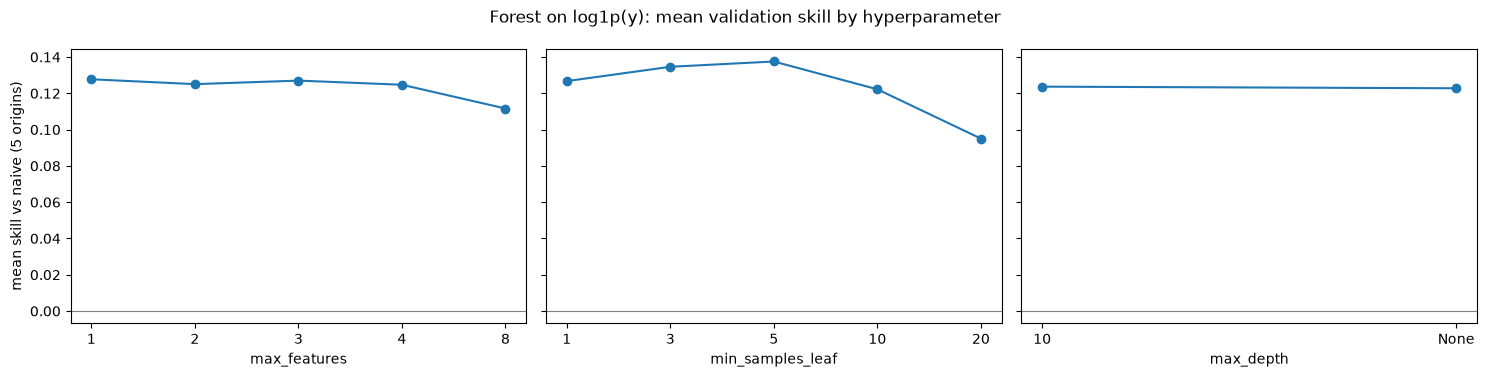

    MAE_3_origins  skill_5
mf                        
1          25.137    0.128
2          25.653    0.125
3          25.912    0.127
4          26.154    0.125
8          26.880    0.112
best forest configuration by mean skill: log forest mf=1 leaf=1 depth=10 {'max_features': 1, 'min_samples_leaf': 1, 'max_depth': 10}


In [10]:
# How each axis moves the forest's mean skill, averaged over the other two.
fg = forest_grid.copy()
fg[["mf", "leaf", "depth"]] = [(int(a), int(b), c) for a, b, c in
                               fg.index.str.extract(r"mf=(\d+) leaf=(\d+) depth=(\w+)").to_numpy()]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, col, label in zip(axes, ["mf", "leaf", "depth"], ["max_features", "min_samples_leaf", "max_depth"]):
    by_value = fg.groupby(col)["skill_5"].mean()
    ax.plot(range(len(by_value)), by_value.to_numpy(), marker="o")
    ax.set_xticks(range(len(by_value)), [str(v) for v in by_value.index])  # categorical: depth includes None
    ax.set_xlabel(label)
    ax.axhline(0, color="grey", lw=0.8)
axes[0].set_ylabel("mean skill vs naive (5 origins)")
fig.suptitle("Forest on log1p(y): mean validation skill by hyperparameter")
fig.tight_layout()
fig.savefig(ASSETS / "demand-rf-v2-grid.png", dpi=150, bbox_inches="tight")
plt.show()
print(fg.groupby("mf")[["MAE_3_origins", "skill_5"]].mean().round(3).to_string())

BEST_FOREST = forest_grid.index[0]
BEST_FOREST_PARAMS = dict(zip(["max_features", "min_samples_leaf", "max_depth"],
                              [int(fg.loc[BEST_FOREST, "mf"]), int(fg.loc[BEST_FOREST, "leaf"]),
                               None if fg.loc[BEST_FOREST, "depth"] == "None" else int(fg.loc[BEST_FOREST, "depth"])]))
print("best forest configuration by mean skill:", BEST_FOREST, BEST_FOREST_PARAMS)

**Reading.** The best configuration is a forest fitted on `log1p(y)` with **`max_features = 1`,
`min_samples_leaf = 1`, `max_depth = 10`**. Its three-origin MAE of **23.97** is the first tree-based
result to beat the linear models on the project's own metric (ElasticNet 24.17, v2 24.32), and its
mean skill is +0.163, with wins on all five origins. Its pooled volume ratio (0.799) still fails
rule 3(b).

- **`max_features` is the axis that matters.** Averaged over the other two axes, mean skill falls
  steadily from +0.128 with one predictor per split to +0.112 with all eight, which is
  `forest_v1`'s setting. With one predictor per split, each split draws a single history column at
  random. That works here because the six history columns are near substitutes (Section 4.3.7.5),
  so any of them can make a useful split, and the trees end up far less correlated with each other.
- **Leaves of 1 to 5 rows are all close; 20 is clearly worse**, and capping the depth at 10 changes
  almost nothing (mean skill 0.124 against 0.123 uncapped).
- **The best configuration sits on the edge of the grid** for `max_features` and `min_samples_leaf`,
  but both are at their smallest possible values, so the grid cannot be extended in that direction.
- **Gradient boosting's best configuration** (`learning_rate = 0.03`, 15 leaves, leaves of at least
  10 rows) reaches +0.142 with a volume ratio of 0.997. It is eligible, but it trails the log forest
  on skill.

## 7. The volume bias of a log-scale fit — corrections and a blend with the naive forecast

Every model fit on `log1p(y)` under-predicts total volume, the retransformation bias Section 4.3.7.5
diagnosed for Linear Regression: `expm1` of a mean in log space is below the mean in item space.
Rule 3(b) rejects any candidate whose pooled volume ratio leaves [0.90, 1.10], so the best forest
of Section 6 cannot be selected as it stands. Three remedies are tested on it, each fitted without
touching the validation month it is scored on:

- **Ratio calibration.** Multiply predictions by `Σy / Σŷ` over the training window, using the
  forest's out-of-bag predictions, so no training row is scored by trees that saw it.
- **Duan's smearing** [2], with the out-of-bag log residuals — the correction Section 4.3.7.7
  rejected for Linear Regression.
- **A blend with the naive forecast**, `w · forest + (1 − w) · last month's value`, over a fixed grid
  of weights. The naive forecast over-predicts total volume (Section 4 reports its ratio) where the
  log forest under-predicts, and the two err on different rows, so a convex combination can cancel
  part of the bias without scaling every prediction. `w` is a hyperparameter like any other, chosen
  on the same five origins.

In [11]:
def forest_corrected(mode, **params):
    params = {"n_estimators": 300, "random_state": RANDOM_STATE, "n_jobs": -1, "oob_score": True} | params
    def fn(tr, va):
        est = RandomForestRegressor(**params).fit(tr[APPROVED_X], np.log1p(tr[TARGET]))
        pred_log = est.predict(va[APPROVED_X])
        oob = est.oob_prediction_
        ok = np.isfinite(oob)
        y_tr = tr[TARGET].to_numpy(dtype=float)[ok]
        if mode == "ratio":
            return np.expm1(pred_log) * y_tr.sum() / np.expm1(oob[ok]).sum()
        if mode == "duan":
            return np.exp(pred_log) * np.mean(np.exp(np.log1p(y_tr) - oob[ok])) - 1
        raise ValueError(mode)
    return fn


def blend(fn, weight):
    return lambda tr, va: weight * fn(tr, va) + (1 - weight) * naive_forecast(va)


best_forest_fn = forest(log_target=True, **BEST_FOREST_PARAMS)
score(f"{BEST_FOREST} + ratio calibration (OOB)", forest_corrected("ratio", **BEST_FOREST_PARAMS), "bias")
score(f"{BEST_FOREST} + Duan smearing (OOB)", forest_corrected("duan", **BEST_FOREST_PARAMS), "bias")
BLEND_WEIGHTS = [0.9, 0.8, 0.7, 0.6, 0.5]
for w in BLEND_WEIGHTS:
    score(f"blend {w:.1f} x best log forest + {1 - w:.1f} x naive", blend(best_forest_fn, w), "bias")
summary(names=[BEST_FOREST, "naive (last month)"] + [n for n in CANDIDATES if CANDIDATES[n]["stage"] == "bias"]).round(3)

,stage,MAE_3_origins,MAE_5_origins,skill_5,skill_obs_5,wins,volume_ratio,in_contract,eligible
candidate,,,,,,,,,
blend 0.8 x best log forest + 0.2 x naive,bias,23.723,29.681,0.182,0.158,5,0.868,True,False
blend 0.7 x best log forest + 0.3 x naive,bias,23.946,29.766,0.178,0.159,5,0.903,True,True
blend 0.9 x best log forest + 0.1 x naive,bias,23.707,29.977,0.176,0.145,5,0.834,True,False
blend 0.6 x best log forest + 0.4 x naive,bias,24.380,30.101,0.168,0.154,5,0.938,True,True
log forest mf=1 leaf=1 depth=10,forest grid,23.966,30.516,0.163,0.125,5,0.799,True,False
blend 0.5 x best log forest + 0.5 x naive,bias,25.098,30.721,0.150,0.139,5,0.973,True,True
log forest mf=1 leaf=1 depth=10 + ratio calibration (OOB),bias,31.853,34.832,0.009,-0.022,3,1.183,True,False
naive (last month),reference,30.980,35.882,0.000,0.000,0,1.148,True,False
log forest mf=1 leaf=1 depth=10 + Duan smearing (OOB),bias,32.575,35.479,-0.006,-0.028,3,1.223,True,False


**Reading.** The two multiplicative corrections fix the total and ruin the forecast. Both push the
pooled volume ratio above 1.18, and mean skill falls to about zero (+0.009 and −0.006). This is the
same failure Section 4.3.7.7 recorded for Linear Regression: one factor large enough to restore the
volume of the few large units inflates every small forecast, where most of the rows are.

**The blend works.** Mixing in last month's value raises skill *and* volume together:

| Forest weight `w` | 1.0 (plain) | 0.9 | 0.8 | 0.7 | 0.6 | 0.5 |
|---|---|---|---|---|---|---|
| Mean skill, 5 origins | 0.163 | 0.176 | 0.182 | 0.178 | 0.168 | 0.150 |
| Pooled volume ratio | 0.799 | 0.834 | 0.868 | **0.903** | 0.938 | 0.973 |

Skill peaks at `w = 0.8`, but that blend still predicts only 86.8% of the volume. **`w = 0.7` is the
highest-skill blend inside the volume band.** The skill gain over the plain forest shows that the two
forecasts make partly independent errors, which a forecast combination can exploit.

## 8. A hurdle model with a median-based zero rule

Notebook 17's Section 11 tested a two-stage hurdle and combined its parts as
`P(y > 0) × E[y | y > 0]`. That product is the conditional **mean**, the right combination for
squared error but not for MAE: when `P(y > 0) < 0.5` the conditional median is exactly **0**. The
hurdle is re-tested with that zero rule: a forest classifier predicts whether the unit bills at all,
and where it does, the best log forest of Section 6, fitted on positive rows only, predicts how much.

Only the zero decision follows from the median. The amount predicted above the threshold is the
back-transformed output of a forest fitted by squared error on `log1p(y)`, a geometric-type central
value of the positive amounts, not the conditional median of the full distribution. The hurdle as a
whole is therefore motivated by MAE, not an MAE-optimal forecast.

In [12]:
def hurdle(threshold=0.5, **params):
    def fn(tr, va):
        occurred = (tr[TARGET] > 0).to_numpy()
        clf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE,
                                     n_jobs=-1).fit(tr[APPROVED_X], occurred)
        positives = tr[occurred]
        reg = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1, **params)
        reg.fit(positives[APPROVED_X], np.log1p(positives[TARGET]))
        p_bill = clf.predict_proba(va[APPROVED_X])[:, 1]
        return np.where(p_bill >= threshold, np.expm1(reg.predict(va[APPROVED_X])), 0.0)
    return fn


score("hurdle, zero when P(bill) < 0.5", hurdle(**BEST_FOREST_PARAMS), "hurdle")
summary(names=["naive (last month)", BEST_FOREST, "hurdle, zero when P(bill) < 0.5"]).round(3)

,stage,MAE_3_origins,MAE_5_origins,skill_5,skill_obs_5,wins,volume_ratio,in_contract,eligible
candidate,,,,,,,,,
"hurdle, zero when P(bill) < 0.5",hurdle,25.372,29.968,0.165,0.180,5,1.023,True,True
log forest mf=1 leaf=1 depth=10,forest grid,23.966,30.516,0.163,0.125,5,0.799,True,False
naive (last month),reference,30.980,35.882,0.000,0.000,0,1.148,True,False


**Reading.** With the median-based zero rule, the hurdle becomes competitive, unlike notebook 17's
product version. It has the **best observed-row skill of any candidate (+0.180)** and a volume
ratio of 1.023, it beats the naive forecast on all five origins, and it is eligible. Its mean skill
(+0.165) is below the best blends, however, because predicting an exact zero whenever
`P(bill) < 0.5` costs more on the units that do bill than it saves on the quiet ones. It is the
closest alternative to the selected model, and the conclusions keep it as a candidate for future
origins.

## 9. Predictors outside the contract — exploratory only

SHAP (Section 4.4.5.5) traced the forest's largest errors to sudden stops and starts that no
combination of the eight approved predictors can anticipate. Two groups of candidates available at
forecast time were therefore tried on the best configuration, both built in Section 1.1 from the
same usable, strictly-prior history as the approved lags:

- **Series identity:** the treatment line (two indicators) and the provider state (an integer code).
  They are grouping keys today, excluded from `X` by notebook 13.
- **History shape:** months since the combination's first claim (`AGE_M`), billed months among the
  last three and six (`NZ_3M`, `NZ_6M`), months since the last billed month (`SINCE_LAST_NZ`), the
  six-month maximum (`MAX_6M`), and two ratios of approved features (`RATIO_1M_6M`, `TREND_3_6`).

None of them is `APPROVED` in notebook 13's contract, so by rule 3(c) none can be selected here,
whatever it scores. The point is to learn whether the contract is worth extending.

In [13]:
for label, extra in [("line + state", LINE_UF_X), ("history shape", SHAPE_X),
                     ("line + state + history shape", LINE_UF_X + SHAPE_X)]:
    score(f"best log forest + {label}", forest(log_target=True, x=APPROVED_X + extra, **BEST_FOREST_PARAMS),
          "features", in_contract=False)
summary(names=[BEST_FOREST] + [n for n in CANDIDATES if CANDIDATES[n]["stage"] == "features"]).round(3)

,stage,MAE_3_origins,MAE_5_origins,skill_5,skill_obs_5,wins,volume_ratio,in_contract,eligible
candidate,,,,,,,,,
best log forest + line + state,features,23.700,30.423,0.168,0.131,4,0.786,False,False
log forest mf=1 leaf=1 depth=10,forest grid,23.966,30.516,0.163,0.125,5,0.799,True,False
best log forest + history shape,features,24.200,30.743,0.158,0.123,5,0.769,False,False
best log forest + line + state + history shape,features,24.257,31.045,0.153,0.117,5,0.742,False,False


**Reading.** None of the extra predictors earns a change to the contract yet.

- **Line and state give a marginal gain:** mean skill +0.168 against +0.163, and three-origin MAE
  23.70 against 23.97. That is small beside the fold-to-fold spread, and the win count drops to
  four of five. The line identifies the drug-heavy `advanced` series (Section 4.3.11.1), so this is
  the one group worth a formal proposal in notebook 13's contract.
- **History shape makes the forecast worse** (+0.158), and so does combining both groups (+0.153).
  Counts of billed months and months since the last bill describe the same history the lags and
  rolling means already carry, so they add noise rather than signal on a panel this small.

The sudden stops and starts SHAP identified in `forest_v1` therefore stay out of reach of anything
derivable from the claims history alone. That points back to the external signals behind
Section 4.3.6's integration gates.

## 10. Selection under the rule of Section 2

Every candidate scored above goes into one leaderboard, and the rule picks the winner
mechanically. The old three-origin MAE is shown next to it so the result can be read against
Section 4.3.10.1's leaderboard.

In [14]:
leaderboard = summary()
eligible = leaderboard[leaderboard["eligible"]]
if eligible.empty:
    raise RuntimeError("No candidate satisfies the rule of Section 2: forest_v1 stays as it is.")
WINNER = eligible.index[0]
print(f"{len(leaderboard)} candidates scored | {len(eligible)} eligible | selected: {WINNER}")
assert WINNER == "blend 0.7 x best log forest + 0.3 x naive", f"documented winner not reproduced: {WINNER}"
check_documented("winner mean skill (5 origins)", leaderboard.loc[WINNER, "skill_5"], 0.178)
check_documented("winner MAE (3 origins)", leaderboard.loc[WINNER, "MAE_3_origins"], 23.946)
show = ["naive (last month)", "forest_v1 (rf_deep_large)", "linear regression v2", "ElasticNet (notebook 18)",
        "forest_v1 hyperparameters, log1p target", BEST_FOREST, boost_grid.index[0],
        "hurdle, zero when P(bill) < 0.5"]
show = list(dict.fromkeys(list(eligible.index[:5]) + show))
display(leaderboard.loc[show].round(3))
per_origin(show).round(2)

85 candidates scored | 23 eligible | selected: blend 0.7 x best log forest + 0.3 x naive


,stage,MAE_3_origins,MAE_5_origins,skill_5,skill_obs_5,wins,volume_ratio,in_contract,eligible
candidate,,,,,,,,,
blend 0.7 x best log forest + 0.3 x naive,bias,23.946,29.766,0.178,0.159,5,0.903,True,True
blend 0.6 x best log forest + 0.4 x naive,bias,24.380,30.101,0.168,0.154,5,0.938,True,True
"hurdle, zero when P(bill) < 0.5",hurdle,25.372,29.968,0.165,0.180,5,1.023,True,True
blend 0.5 x best log forest + 0.5 x naive,bias,25.098,30.721,0.150,0.139,5,0.973,True,True
boosting lr=0.03 leaves=15 leaf=10,boosting grid,26.540,30.788,0.142,0.138,4,0.997,True,True
naive (last month),reference,30.980,35.882,0.000,0.000,0,1.148,True,False
forest_v1 (rf_deep_large),reference,31.011,33.951,0.037,0.076,3,1.179,True,False
linear regression v2,reference,24.323,31.288,0.150,0.130,4,0.739,True,False
ElasticNet (notebook 17),reference,24.168,31.041,0.156,0.137,4,0.746,True,False


origin,2025-05,2025-06,2025-07,2025-08,2025-09
candidate,,,,,
blend 0.7 x best log forest + 0.3 x naive,39.42,37.57,28.02,23.05,20.76
blend 0.6 x best log forest + 0.4 x naive,39.47,37.90,28.51,23.24,21.39
"hurdle, zero when P(bill) < 0.5",36.39,37.34,28.79,25.67,21.66
blend 0.5 x best log forest + 0.5 x naive,39.78,38.53,29.54,23.62,22.14
boosting lr=0.03 leaves=15 leaf=10,36.44,37.88,30.96,29.02,19.64
naive (last month),43.13,43.34,37.47,28.74,26.73
forest_v1 (rf_deep_large),37.07,39.65,33.34,32.04,27.65
linear regression v2,44.96,38.52,33.16,21.49,18.32
ElasticNet (notebook 17),44.59,38.11,32.75,21.38,18.37


### 10.1 How optimistic is the winning score?

The winner's score is the maximum over some 80 candidates evaluated on the same five months, so it
is biased upward. Nested selection measures by how much, in the spirit of notebook 15's nested
cross-validation: for each of the July, August and September origins, the rule is applied using
**only the origins before it** (rule 3(a) scaled to the origins available, rule 3(b) on their pooled
volume), and the candidate it picks is scored on that origin, which took no part in the choice.

In [15]:
f = pd.DataFrame(FOLD_ROWS)
f["skill"] = 1 - f["MAE"] / f["naive_MAE"]
contract_ok = {c for c, spec in CANDIDATES.items() if spec["in_contract"] and c != "naive (last month)"}
nested = []
for k in range(2, N_ORIGINS):
    past = f[f["origin"].isin(ORIGINS[:k]) & f["candidate"].isin(contract_ok)]
    g = past.groupby("candidate")
    stats = pd.DataFrame({"skill": g["skill"].mean(), "wins": g.apply(lambda d: (d["MAE"] < d["naive_MAE"]).sum()),
                          "vr": g["sum_pred"].sum() / g["sum_true"].sum()})
    ok = stats[stats["wins"].ge(k - 1) & stats["vr"].between(*VOLUME_BAND)].sort_values("skill", ascending=False)
    pick = ok.index[0]
    outer = f[(f["origin"] == ORIGINS[k]) & (f["candidate"] == pick)]["skill"].iloc[0]
    winner_outer = f[(f["origin"] == ORIGINS[k]) & (f["candidate"] == WINNER)]["skill"].iloc[0]
    nested.append({"scored origin": f"{ORIGINS[k]:%Y-%m}", "selected on earlier origins": pick,
                   "its skill there": outer, "final winner's skill there": winner_outer})
nested = pd.DataFrame(nested)
display(nested.round(3))
nested_mean, winner_mean = nested["its skill there"].mean(), nested["final winner's skill there"].mean()
print(f"nested estimate (mean skill, Jul-Sep): {nested_mean:.3f} | "
      f"non-nested winner on the same origins: {winner_mean:.3f} | optimism {winner_mean - nested_mean:.3f}")
check_documented("nested estimate", nested_mean, 0.132)
check_documented("winner skill on the nested origins", winner_mean, 0.224)

,scored origin,selected on earlier origins,its skill there,final winner's skill there
0,2025-07,boosting lr=0.03 leaves=31 leaf=10,0.100,0.252
1,2025-08,"hurdle, zero when P(bill) < 0.5",0.107,0.198
2,2025-09,"hurdle, zero when P(bill) < 0.5",0.190,0.223


nested estimate (mean skill, Jul-Sep): 0.132 | non-nested winner on the same origins: 0.224 | optimism 0.092


### 10.2 Does the result depend on the random seed or the tree count?

The winner is refit with three other seeds and with 600 trees, the count used for the final model.

In [16]:
# The winner is expected to be a (possibly blended) log forest from Sections 6-7; any other kind of
# winner would need its own persistence code in Section 12, so the notebook stops rather than guess.
if WINNER == BEST_FOREST:
    WINNER_WEIGHT = 1.0
elif WINNER.startswith("blend ") and WINNER.endswith("x naive"):
    WINNER_WEIGHT = float(WINNER.split()[1])
else:
    raise RuntimeError(f"Selected candidate {WINNER!r} is not a log forest: extend Section 12 before persisting it.")
FINAL_PARAMS = {"n_estimators": 600} | BEST_FOREST_PARAMS
print("winner = ", f"{WINNER_WEIGHT} x log forest {BEST_FOREST_PARAMS} + {1 - WINNER_WEIGHT:.1f} x naive")

for seed in (1, 7, 2024):
    score(f"winner, seed {seed}", blend(forest(log_target=True, random_state=seed, **BEST_FOREST_PARAMS),
                                         WINNER_WEIGHT), "stability")
score("winner, 600 trees", blend(forest(log_target=True, **FINAL_PARAMS), WINNER_WEIGHT), "stability")
stability = summary(names=[WINNER] + [n for n in CANDIDATES if CANDIDATES[n]["stage"] == "stability"])
display(stability.round(3))
print(f"skill range across seeds and tree counts: {stability['skill_5'].min():.3f} .. {stability['skill_5'].max():.3f}")

winner =  0.7 x log forest {'max_features': 1, 'min_samples_leaf': 1, 'max_depth': 10} + 0.3 x naive


,stage,MAE_3_origins,MAE_5_origins,skill_5,skill_obs_5,wins,volume_ratio,in_contract,eligible
candidate,,,,,,,,,
"winner, 600 trees",stability,23.945,29.718,0.180,0.161,5,0.903,True,True
blend 0.7 x best log forest + 0.3 x naive,bias,23.946,29.766,0.178,0.159,5,0.903,True,True
"winner, seed 2024",stability,23.912,29.795,0.178,0.159,5,0.906,True,True
"winner, seed 1",stability,23.979,29.907,0.175,0.157,5,0.902,True,True
"winner, seed 7",stability,24.297,29.860,0.174,0.154,5,0.909,True,True


skill range across seeds and tree counts: 0.174 .. 0.180


**Reading.** The rule selects **`0.7 × log forest + 0.3 × last month's value`**, with the forest
configured as in Section 6. It leads the eligible candidates on mean skill (+0.178), and it also has
the lowest three-origin MAE among the eligible ones (23.95), below ElasticNet's 24.17. It beats the
naive forecast on every origin. Against the linear models it wins May to July and loses August and
September (23.05 against 21.38, and 20.76 against 18.37), so the two families are strong on
different months, and a single three-origin average hides that.

**The winning score is optimistic.** Nested selection picks a different candidate on each outer
origin: gradient boosting in July, and the hurdle in August and September. The candidates it picks
reach a mean skill of **0.132** on July to September, against 0.224 for the final winner on the
same months, an optimism of 0.092 skill points. That is much larger than notebook 15's tree
(Section 4.3.8.3), which is expected after roughly 80 candidates on five origins. It means the top
few eligible candidates are not reliably separable on this much data. Even the nested estimate is
well above `forest_v1`'s +0.037, however, so the improvement over the forest being replaced does not
depend on picking the single best configuration.

**Seeds and tree count do not matter.** Across four seeds and 300 or 600 trees, mean skill stays
between 0.174 and 0.180, and the volume ratio stays between 0.902 and 0.909.

## 11. The holdout — read once, after the selection is locked

The selection above is final. The October–December holdout is now scored for the selected model,
fitted on all 7,716 training rows with 600 trees, next to the references it has to be read
against. `forest_v1` and Linear Regression v2 must reproduce the holdout MAE notebook 17 records
(18.141 and 19.219). The ElasticNet notebook 18 selected has never been read on the holdout; its
selection is already locked in notebook 18, so reading it here cannot change it, and it closes one of
the gaps Section 4.4.3 lists.

In [17]:
y_hold = holdout[TARGET].to_numpy(dtype=float)
obs_mask = ~holdout["IS_STRUCTURAL_ZERO"].to_numpy()
pred_naive = naive_forecast(holdout)
naive_mae_all = mean_absolute_error(y_hold, pred_naive)
naive_mae_obs = mean_absolute_error(y_hold[obs_mask], pred_naive[obs_mask])

HOLDOUT_MODELS = {
    "Seasonal-naive baseline": lambda tr, va: naive_forecast(va),
    "Random Forest v1 (rf_deep_large)": forest(**RF_V1),
    "Linear Regression v2": linear(LinearRegression(), "median"),
    "ElasticNet (notebook 18)": linear(EN_V17, "mean"),
    "Random Forest v2 (selected)": blend(forest(log_target=True, **FINAL_PARAMS), WINNER_WEIGHT),
}
hold_pred = {name: np.clip(fn(train, holdout), 0, None) for name, fn in HOLDOUT_MODELS.items()}

rows = []
for name, pred in hold_pred.items():
    m_all = evaluate(y_hold, pred, baseline_mae=naive_mae_all)
    m_obs = evaluate(y_hold, pred, mask=obs_mask, baseline_mae=naive_mae_obs)
    rows.append({"Model": name, **{k: m_all[k] for k in ["MAE", "RMSE", "R2", "MAE_log1p", "volume_ratio", "skill_vs_naive"]},
                 **{f"{k}_obs": m_obs[k] for k in ["MAE", "RMSE", "R2", "skill_vs_naive"]}})
holdout_table = pd.DataFrame(rows).set_index("Model")
assert abs(holdout_table.loc["Random Forest v1 (rf_deep_large)", "MAE"] - 18.141) < 5e-3, "forest_v1 not reproduced"
assert abs(holdout_table.loc["Linear Regression v2", "MAE"] - 19.219) < 5e-3, "linear regression v2 not reproduced"
v2_hold = holdout_table.loc["Random Forest v2 (selected)"]
for label, key, documented in [("forest_v2 holdout MAE", "MAE", 18.157), ("forest_v2 skill, all rows", "skill_vs_naive", 0.079),
                               ("forest_v2 skill, observed rows", "skill_vs_naive_obs", 0.030),
                               ("forest_v2 volume ratio", "volume_ratio", 0.662)]:
    check_documented(label, v2_hold[key], documented)
print(f"holdout: {len(holdout):,} rows ({obs_mask.sum():,} observed) | naive MAE {naive_mae_all:.3f} / {naive_mae_obs:.3f}")
holdout_table.round(3)

holdout: 3,810 rows (1,674 observed) | naive MAE 19.724 / 38.216


,MAE,RMSE,R2,MAE_log1p,volume_ratio,skill_vs_naive,MAE_obs,RMSE_obs,R2_obs,skill_vs_naive_obs
Model,,,,,,,,,,
Seasonal-naive baseline,19.724,74.895,0.611,0.522,1.043,0.000,38.216,108.679,0.605,0.000
Random Forest v1 (rf_deep_large),18.141,91.405,0.421,0.583,0.987,0.080,30.155,91.757,0.718,0.211
Linear Regression v2,19.219,79.330,0.564,0.500,0.565,0.026,39.626,117.108,0.541,-0.037
ElasticNet (notebook 17),18.959,78.246,0.576,0.503,0.583,0.039,38.889,115.268,0.555,-0.018
Random Forest v2 (selected),18.157,69.803,0.662,0.526,0.662,0.079,37.051,102.196,0.650,0.030


### 11.1 Is the difference larger than noise? A by-operator bootstrap

Section 4.3.7.8 ran this test for Linear Regression v1 only. Here every model is compared with the
naive forecast and with `forest_v1`, resampling whole **operators** 2,000 times, so an operator's
autocorrelated months are never treated as independent evidence.

In [18]:
rng = np.random.default_rng(RANDOM_STATE)
ops = holdout["ID_PLANO"].astype(str).to_numpy()
op_codes, op_index = np.unique(ops, return_inverse=True)
draws = rng.integers(0, len(op_codes), size=(2000, len(op_codes)))
weights = np.stack([np.bincount(d, minlength=len(op_codes)) for d in draws])   # times each operator is drawn


def boot_mae(pred, mask):
    err = np.abs(y_hold - pred)
    sums = np.bincount(op_index[mask], weights=err[mask], minlength=len(op_codes))
    counts = np.bincount(op_index[mask], minlength=len(op_codes))
    return (weights @ sums) / (weights @ counts)


boot_rows = []
for rows_label, mask in [("all rows", np.ones(len(y_hold), bool)), ("observed rows", obs_mask)]:
    base_naive, base_v1 = boot_mae(pred_naive, mask), boot_mae(hold_pred["Random Forest v1 (rf_deep_large)"], mask)
    for name, pred in hold_pred.items():
        if name == "Seasonal-naive baseline":
            continue
        b = boot_mae(pred, mask)
        for ref_label, ref_b in [("naive", base_naive), ("forest_v1", base_v1)]:
            if name.startswith("Random Forest v1") and ref_label == "forest_v1":
                continue
            d = b - ref_b
            boot_rows.append({"rows": rows_label, "model": name, "vs": ref_label, "MAE diff (mean)": d.mean(),
                              "95% CI low": np.quantile(d, 0.025), "95% CI high": np.quantile(d, 0.975),
                              "better in % of resamples": (d < 0).mean() * 100})
bootstrap = pd.DataFrame(boot_rows)
bootstrap.round(3)

,rows,model,vs,MAE diff (mean),95% CI low,95% CI high,better in % of resamples
0,all rows,Random Forest v1 (rf_deep_large),naive,-1.468,-4.365,2.843,79.65
1,all rows,Linear Regression v2,naive,-0.450,-2.048,1.366,70.50
2,all rows,Linear Regression v2,forest_v1,1.018,-2.737,3.492,23.80
3,all rows,ElasticNet (notebook 17),naive,-0.709,-2.269,1.080,79.45
4,all rows,ElasticNet (notebook 17),forest_v1,0.759,-2.970,3.186,28.55
5,all rows,Random Forest v2 (selected),naive,-1.517,-2.912,-0.035,97.75
6,all rows,Random Forest v2 (selected),forest_v1,-0.049,-3.665,2.106,45.70
7,observed rows,Random Forest v1 (rf_deep_large),naive,-7.986,-11.593,-4.413,100.00
8,observed rows,Linear Regression v2,naive,1.524,-1.841,5.452,21.50
9,observed rows,Linear Regression v2,forest_v1,9.510,7.130,12.430,0.00


### 11.2 At the grain the personas act on: operator × UF × month

Section 4.3.9.7 scored `forest_v1` summed to `operator × UF × month` cells against last month's true
cell total (skill +0.039 under the current line rule). The same computation is repeated for every
model, on every eligible holdout row of the as-of panel (including groups whose quantity cannot be
measured, as notebook 17 does), and `forest_v1` must reproduce notebook 17's cell MAE (30.957).

In [19]:
CELL = ["ID_PLANO", "UF_PRESTADOR", "MES"]
scoring = panel[(panel["MES"] >= cutoff)].copy()
raw_cells = (base.assign(_bundled=base["IND_PACOTE_1"].eq(1)).groupby(CELL, observed=True)
             .agg(y=("QT_ITEM_EVENTO_INFORMADO", lambda s: s.sum(min_count=1)),
                  bundled=("_bundled", "sum")).reset_index())
prev_cells = raw_cells.assign(MES=raw_cells["MES"] + pd.offsets.MonthBegin(1)).rename(
    columns={"y": "prev_y", "bundled": "prev_bundled"})

train_panel = train  # the same 7,716 rows every holdout model above was fitted on
for name, fn in HOLDOUT_MODELS.items():
    scoring[name] = np.clip(fn(train_panel, scoring), 0, None)
cells = (scoring.groupby(CELL, observed=True)[list(HOLDOUT_MODELS)].sum().reset_index()
         .merge(raw_cells, on=CELL, how="left").merge(prev_cells, on=CELL, how="left"))
cells["y"] = cells["y"].fillna(0.0)
cells["bundled"] = cells["bundled"].fillna(0)
cells["naive_true"] = cells["prev_y"].fillna(0.0)
ev = cells[cells["bundled"] == 0]
naive_ref = mean_absolute_error(ev["y"], ev["naive_true"])
grain = pd.DataFrame([{
    "prediction": name, "cell_MAE": mean_absolute_error(ev["y"], ev[name]),
    "cell_skill": 1 - mean_absolute_error(ev["y"], ev[name]) / naive_ref,
    "mean_pred_over_mean_truth": ev[name].mean() / ev["y"].mean()} for name in HOLDOUT_MODELS]).set_index("prediction")
assert abs(grain.loc["Random Forest v1 (rf_deep_large)", "cell_MAE"] - 30.957) < 5e-3, "notebook 17's cell MAE not reproduced"
print(f"{len(ev):,} measurable operator x UF x month cells | naive reference (last month's true total): MAE {naive_ref:.3f}")
check_documented("forest_v2 operator-grain skill", grain.loc["Random Forest v2 (selected)", "cell_skill"], 0.086)
grain.round(3)

2,031 measurable operator x UF x month cells | naive reference (last month's true total): MAE 32.201


,cell_MAE,cell_skill,mean_pred_over_mean_truth
prediction,,,
Seasonal-naive baseline,32.186,0.000,1.057
Random Forest v1 (rf_deep_large),30.957,0.039,0.990
Linear Regression v2,30.889,0.041,0.579
ElasticNet (notebook 17),30.496,0.053,0.598
Random Forest v2 (selected),29.438,0.086,0.661


### 11.3 How much of these numbers is the random seed?

Every number above uses `random_state = 42` and the pinned row order of Section 1. Both forests are
refit here with ten other seeds on the same training rows, to show how far a different seed moves
the holdout read. Nothing is selected from this: the seed stays 42, and the table only gives the
precision with which the holdout numbers of both forests should be read.

In [20]:
noise_rows = []
for seed in range(10):
    for name, fn in [("Random Forest v1 (rf_deep_large)", forest(random_state=seed, **RF_V1)),
                     ("Random Forest v2 (selected)",
                      blend(forest(log_target=True, random_state=seed, **FINAL_PARAMS), WINNER_WEIGHT))]:
        pred = np.clip(fn(train, holdout), 0, None)
        m_all = evaluate(y_hold, pred, baseline_mae=naive_mae_all)
        m_obs = evaluate(y_hold, pred, mask=obs_mask, baseline_mae=naive_mae_obs)
        noise_rows.append({"model": name, "seed": seed, "MAE": m_all["MAE"], "skill": m_all["skill_vs_naive"],
                           "skill_obs": m_obs["skill_vs_naive"], "volume_ratio": m_all["volume_ratio"]})
seed_noise = pd.DataFrame(noise_rows).groupby("model")[["MAE", "skill", "skill_obs", "volume_ratio"]].agg(["min", "mean", "max"])
seed_noise.round(3)

MAE                  skill               skill_obs               volume_ratio              
                                     min    mean     max    min   mean    max       min   mean    max          min   mean    max
model                                                                                                                           
Random Forest v1 (rf_deep_large)  18.100  18.206  18.293  0.073  0.077  0.082     0.206  0.208  0.212        0.981  0.986  0.989
Random Forest v2 (selected)       18.095  18.175  18.266  0.074  0.079  0.083     0.025  0.029  0.035        0.661  0.665  0.671

**Reading.** This is the single read of the holdout, and the result is mixed.

**Where `forest_v2` improves:**

- **All rows.** Its MAE (18.157) is level with `forest_v1`'s (18.141), with skill +0.079 against
  +0.080. It has the **lowest RMSE (69.80) and the highest R² (0.662) of any candidate evaluated in
  this project**, ahead of Linear Regression v1 (72.30 and 0.638, Section 4.3.10.3) and far ahead of
  `forest_v1` (91.41 and 0.421).
- **It is the only model whose all-rows gain over the naive forecast the bootstrap confirms**: mean
  MAE difference −1.52, 95% interval [−2.91, −0.04], better in 97.8% of resamples. `forest_v1`'s
  interval straddles zero ([−4.37, 2.84]).
- **Operator grain.** Summed to `operator × UF × month`, its skill is **+0.086**, more than double
  `forest_v1`'s +0.039 and ahead of every other model.

**Where it does not:**

- **Observed rows.** Its skill is +0.030 against `forest_v1`'s +0.211, and the bootstrap confirms
  the difference: MAE 6.92 higher, 95% interval [5.08, 8.84]. On the rows that billed, `forest_v1`
  remains clearly the better forecaster.
- **Aggregate volume.** The pooled volume ratio, 0.903 on validation, is **0.662** on the holdout.
  The volume guardrail that selected `w = 0.7` did not carry over to October–December. Holdout
  volume is dominated by a few large `advanced`-line units in Amazonas. The log fit shrinks exactly
  those units, and last month's value, 30% of the blend, cannot make up the shortfall.

Both findings point to the same mechanism. The log fit trades accuracy on the largest units for
accuracy on the typical unit, which helps RMSE and R² (fewer huge over-predictions such as the
sudden stop of Section 4.4.5.5) and hurts observed-row MAE and total volume.

**ElasticNet's first holdout read** matches Linear Regression v2 closely: all-rows skill +0.039,
observed-row skill −0.018 and volume ratio 0.583. Its validation lead over v2 does not turn into a
materially different holdout result.

**How precise these numbers are (Section 11.3).** Across ten other seeds, all-rows MAE ranges from
18.10 to 18.29 for `forest_v1` and from 18.10 to 18.27 for `forest_v2`. The third decimal of either
model's all-rows MAE is therefore noise, and "`forest_v2` ties `forest_v1` on MAE" holds for any
seed. The findings the decision rests on do not move with the seed: observed-row skill stays between
+0.206 and +0.212 for `forest_v1` and between +0.025 and +0.035 for `forest_v2`, and `forest_v2`'s
volume ratio stays between 0.661 and 0.671.

## 12. Outputs — `forest_v2` bundle, prediction base and registry entry

`forest_v1`'s files are left exactly as notebook 17 wrote them; `forest_v2` is written beside them
with the same prediction-base schema, so any consumer can switch between the two by file name.

The bundle stores the forest as a `TransformedTargetRegressor`, so `model.predict()` returns items,
not `log1p` values. The blend with last month's value is stored in the metadata rather than in a
custom class, which would make the bundle impossible to load outside this notebook; the same
approach as Linear Regression v2's `reconstruction_note`. The cell asserts that the stored recipe
reproduces the prediction base exactly.

In [21]:
MODEL_PATH = PROC / "north_region_mama_2025_demand_forest_v2.joblib"
PRED_PARQUET = PROC / "north_region_mama_2025_demand_predictions_forest_v2.parquet"
PRED_CSV = PROC / "north_region_mama_2025_demand_predictions_forest_v2.csv"
REGISTRY_PATH = REGISTRY / "random_forest_v2.json"

forest_v2 = TransformedTargetRegressor(
    regressor=RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **FINAL_PARAMS),
    func=np.log1p, inverse_func=np.expm1, check_inverse=False,
).fit(train[APPROVED_X], train[TARGET])


def predict_v2(model, frame, weight):
    # the stored recipe: weight x forest (items) + (1 - weight) x DEMAND_LAG_1M (0 where missing)
    return np.clip(weight * model.predict(frame[APPROVED_X]) + (1 - weight) * naive_forecast(frame), 0, None)


assert np.allclose(predict_v2(forest_v2, holdout, WINNER_WEIGHT), hold_pred["Random Forest v2 (selected)"]), \
    "the persisted recipe does not reproduce Section 11's predictions"

pred_base = scoring[UNIT_KEYS].copy()
pred_base["volume_previsto"] = predict_v2(forest_v2, scoring, WINNER_WEIGHT)
pred_base["volume_observado"] = scoring[TARGET].where(scoring["USABLE"]).to_numpy()
pred_base["target_measured"] = scoring["USABLE"].to_numpy()
pred_base["is_structural_zero"] = scoring["IS_STRUCTURAL_ZERO"].to_numpy()
pred_base["has_recent_history"] = scoring["DEMAND_LAG_1M"].notna().to_numpy()
q1, q2 = pred_base["volume_previsto"].quantile([1 / 3, 2 / 3])
pred_base["tier"] = np.select([pred_base["volume_previsto"] <= q1, pred_base["volume_previsto"] <= q2],
                              ["baixo", "medio"], default="alto")
pred_base = pred_base.sort_values(["MES", "volume_previsto"], ascending=[True, False])

v2_row, v1_row = holdout_table.loc["Random Forest v2 (selected)"], holdout_table.loc["Random Forest v1 (rf_deep_large)"]
selection_text = (f"Pre-registered rule (notebook 20, Section 2): highest mean skill vs the seasonal-naive forecast over "
                  f"5 expanding origins (May-Sep 2025) among candidates that beat naive on >= {MIN_WINS}/5 origins, keep the "
                  f"pooled validation volume ratio in [{VOLUME_BAND[0]:.2f}, {VOLUME_BAND[1]:.2f}] and use only APPROVED "
                  f"predictors; {len(leaderboard)} candidates scored, holdout read once after selection.")
metadata = {
    "model_name": "random_forest_v2",
    "sklearn_estimator": "TransformedTargetRegressor(RandomForestRegressor, func=log1p, inverse_func=expm1)",
    "features": APPROVED_X, "target": TARGET, "unit_keys": UNIT_KEYS, "random_state": RANDOM_STATE,
    "hyperparameters": FINAL_PARAMS,
    "blend": {"forest_weight": WINNER_WEIGHT, "naive_weight": round(1 - WINNER_WEIGHT, 10),
              "naive_feature": "DEMAND_LAG_1M", "naive_fill_value": 0.0},
    "prediction_recipe": ("clip(forest_weight * model.predict(X[features]) + naive_weight * "
                          "DEMAND_LAG_1M.fillna(0), 0, None)"),
    "selected_on": selection_text,
    "validation": {k: float(leaderboard.loc[WINNER, k]) for k in
                   ["MAE_3_origins", "MAE_5_origins", "skill_5", "skill_obs_5", "volume_ratio"]} | {
                   "wins": int(leaderboard.loc[WINNER, "wins"])},
    "holdout_cutoff": str(cutoff.date()), "train_rows": int(len(train)),
    "holdout_rows_scored": int(len(pred_base)), "holdout_rows_measured": int(len(holdout)),
    "holdout_metrics_all_rows": {"MAE": float(v2_row["MAE"]), "RMSE": float(v2_row["RMSE"]), "R2": float(v2_row["R2"]),
                                 "MAE_log1p": float(v2_row["MAE_log1p"]), "skill": float(v2_row["skill_vs_naive"]),
                                 "volume_ratio": float(v2_row["volume_ratio"])},
    "holdout_metrics_observed_only": {"MAE": float(v2_row["MAE_obs"]), "RMSE": float(v2_row["RMSE_obs"]),
                                      "R2": float(v2_row["R2_obs"]), "skill": float(v2_row["skill_vs_naive_obs"])},
    "operator_grain_skill": float(grain.loc["Random Forest v2 (selected)", "cell_skill"]),
    "supersedes": "north_region_mama_2025_demand_forest_v1.joblib (kept unchanged)",
    "provenance": PROVENANCE,
    "holdout_seed_spread": {k: [round(float(seed_noise.loc["Random Forest v2 (selected)", (k, stat)]), 4)
                                for stat in ("min", "max")] for k in ["MAE", "skill", "skill_obs", "volume_ratio"]},
    "caveats": [
        "treatment_line_primary is a series-partition convention (Section 4.3.11), not a disease stage",
        "operators and combinations first seen after the cutoff are outside the forecast scope",
        "volume_demanda_proxy is billed item quantity, not a patient count",
        "MONTH is still learned only up to September; holdout months reuse September's branch",
    ],
}
joblib.dump({"model": forest_v2, "metadata": metadata}, MODEL_PATH)
reloaded = joblib.load(MODEL_PATH)
assert np.allclose(predict_v2(reloaded["model"], scoring, reloaded["metadata"]["blend"]["forest_weight"]),
                   pred_base.sort_index()["volume_previsto"].to_numpy()), "reloaded bundle does not reproduce the base"
pred_base.to_parquet(PRED_PARQUET, index=False)
pred_base.to_csv(PRED_CSV, index=False)

registry = {
    "model_id": "random_forest_v2", "model_version": "2.0.0", "algorithm": "random_forest", "selected": False,
    "target": {"technical_name": TARGET, "display_name": "Estimated demand volume",
               "unit": "billed item quantity", "aggregation": "sum"},
    "granularity": ["operator_id", "treatment_line", "provider_state", "forecast_month"],
    "features": APPROVED_X,
    "feature_transforms": {c: "none; missing values routed natively by the trees" for c in HISTORY_X},
    "output_transform": (f"{WINNER_WEIGHT} x expm1(forest prediction on log1p(y)) + {1 - WINNER_WEIGHT:.1f} x "
                         "DEMAND_LAG_1M (0 where missing), clipped at 0"),
    "selection_method": selection_text,
    "training_period": {"start": f"{train['MES'].min():%Y-%m}", "end": f"{train['MES'].max():%Y-%m}"},
    "holdout_period": {"start": f"{holdout['MES'].min():%Y-%m}", "end": f"{holdout['MES'].max():%Y-%m}"},
    "metrics": {"mae": round(float(v2_row["MAE"]), 4), "rmse": round(float(v2_row["RMSE"]), 4),
                "r2": round(float(v2_row["R2"]), 4), "mae_log1p": round(float(v2_row["MAE_log1p"]), 4),
                "skill_vs_naive": round(float(v2_row["skill_vs_naive"]), 4),
                "skill_vs_naive_observed": round(float(v2_row["skill_vs_naive_obs"]), 4),
                "volume_ratio": round(float(v2_row["volume_ratio"]), 4)},
    "metrics_caveat": ("Selected on validation only; the holdout was read once, after selection (notebook 20, "
                       "Section 11). See Section 11.1 for which differences the by-operator bootstrap confirms and Section 11.3 "
                       "for the spread across random seeds. "
                       "selected=false: switching the dashboard from forest_v1 is a separate decision."),
    "input_provenance": PROVENANCE,
    "generated_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
}
REGISTRY.mkdir(parents=True, exist_ok=True)
REGISTRY_PATH.write_text(json.dumps(registry, indent=2), encoding="utf-8")

print("wrote:", MODEL_PATH.name, "|", PRED_PARQUET.name, "/", PRED_CSV.name, pred_base.shape, "|", REGISTRY_PATH.name)
print("forest_v1 files untouched:", FOREST_V1_PATH.is_file())
print(pred_base["tier"].value_counts().to_string())
pred_base.head(8)

wrote: north_region_mama_2025_demand_forest_v2.joblib | north_region_mama_2025_demand_predictions_forest_v2.parquet / north_region_mama_2025_demand_predictions_forest_v2.csv (3843, 10) | random_forest_v2.json
forest_v1 files untouched: True
tier
alto     1281
medio    1281
baixo    1281


,ID_PLANO,treatment_line_primary,UF_PRESTADOR,MES,volume_previsto,volume_observado,target_measured,is_structural_zero,has_recent_history,tier
10867,420883,advanced,AM,2025-10-01,1671.921653,3023.0,True,False,True,alto
1162,147828,advanced,AM,2025-10-01,809.847793,0.0,True,True,True,alto
10514,420026,advanced,AM,2025-10-01,725.253821,1578.0,True,False,True,alto
5126,219776,advanced,AM,2025-10-01,711.448614,1376.0,True,False,True,alto
4902,219769,advanced,AM,2025-10-01,630.381126,652.0,True,False,True,alto
6711,230117,advanced,AM,2025-10-01,544.438530,819.0,True,False,True,alto
7084,234693,advanced,AM,2025-10-01,507.491736,480.0,True,False,True,alto
5270,219828,advanced,AM,2025-10-01,494.467505,810.0,True,False,True,alto


In [22]:
# How far does v2 move the published ranking? Same rows, same tercile rule.
v1_base = pd.read_parquet(PROC / "north_region_mama_2025_demand_predictions_forest_v1.parquet")
both = pred_base.merge(v1_base, on=UNIT_KEYS, suffixes=("_v2", "_v1"), validate="one_to_one")
assert len(both) == len(pred_base) == len(v1_base), "v1 and v2 prediction bases do not cover the same rows"
tier_moves = pd.crosstab(both["tier_v1"], both["tier_v2"]).loc[["alto", "medio", "baixo"], ["alto", "medio", "baixo"]]
print(f"rows: {len(both):,} | same tier in v1 and v2: {(both['tier_v1'] == both['tier_v2']).mean():.1%} | "
      f"Spearman of predicted volume: {both['volume_previsto_v1'].rank().corr(both['volume_previsto_v2'].rank()):.3f}")
tier_moves

rows: 3,843 | same tier in v1 and v2: 83.7% | Spearman of predicted volume: 0.922


tier_v2,alto,medio,baixo
tier_v1,,,
alto,1175,106,0
medio,106,959,198
baixo,0,216,1083


**Reading.** `forest_v2` and its prediction base are written beside `forest_v1`'s, which are
untouched, with the same schema and the same 3,843 rows. The registry entry says
`selected: false`: which base the dashboard reads is a separate decision (Section 14).

The two rankings largely agree. 83.7% of rows keep their tier, no row moves between `alto` and
`baixo`, and the Spearman correlation of predicted volume is 0.922. The differences are where
Section 11 says they would be:

- **The sudden stop improves.** `forest_v1`'s largest holdout error (operator 147828, `advanced`, AM,
  October: 0 billed, 2,921 predicted) falls to 810.
- **The largest billing unit gets worse.** Operator 420883 billed 3,023 items; `forest_v1` predicted
  2,866 and `forest_v2` predicts 1,672.

## 13. SHAP — the forest component of `forest_v2`, and the complete recipe

Section 4.4.5 explained `forest_v1` and noted that a retrained or reconfigured forest would need the
analysis re-run. `forest_v2`'s published forecast has three parts: a forest fitted on `log1p(y)`, the
`expm1` back-transform, and a blend that adds 30% of `DEMAND_LAG_1M` directly. This section explains
both levels and does not assume that one carries over to the other:

- **The forest component (this section's first part).** `TreeExplainer` decomposes the persisted
  forest's prediction exactly, on the `log1p` scale. Its SHAP values are in **`log1p` items** and
  describe the forest only. The same 1,000 holdout rows (same seed as notebook 17) are explained for
  `forest_v1`, and the two are compared by share of total |SHAP|, since their units differ.
- **The complete recipe (Section 13.1).** The published item-scale forecast, blend included, is
  explained separately with exact Shapley values, and its ranking is compared with the component's.

In [23]:
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", category=PendingDeprecationWarning, module=r"shap\.")
import shap

bundle = joblib.load(MODEL_PATH)
v2_forest = bundle["model"].regressor_
assert list(bundle["model"].feature_names_in_) == APPROVED_X == list(bundle["metadata"]["features"])

shap_X = holdout[APPROVED_X].sample(min(1000, len(holdout)), random_state=RANDOM_STATE)
t0 = time.perf_counter()
explainer_v2 = shap.TreeExplainer(v2_forest)
shap_v2 = explainer_v2(shap_X)
expected_v2 = float(np.ravel(explainer_v2.expected_value)[0])
gap = float(np.abs(expected_v2 + shap_v2.values.sum(axis=1) - v2_forest.predict(shap_X)).max())
assert gap < 1e-6, f"SHAP not additive on the log1p scale: {gap:.3g}"
print(f"forest_v2 component: {len(shap_X):,} rows in {time.perf_counter() - t0:.1f} s | expected value "
      f"{expected_v2:.3f} log1p (= {np.expm1(expected_v2):.2f} items) | additivity gap {gap:.1e}")

v1_bundle = joblib.load(FOREST_V1_PATH)
t0 = time.perf_counter()
shap_v1 = shap.TreeExplainer(v1_bundle["model"])(shap_X)
print(f"forest_v1: same rows in {time.perf_counter() - t0:.1f} s")

share = pd.DataFrame({
    "v2 component mean |SHAP| (log1p)": np.abs(shap_v2.values).mean(axis=0),
    "v1 mean |SHAP| (items)": np.abs(shap_v1.values).mean(axis=0)}, index=APPROVED_X)
share["v2 component share"] = share.iloc[:, 0] / share.iloc[:, 0].sum()
share["v1 share"] = share.iloc[:, 1] / share.iloc[:, 1].sum()
share["v2 component rank"] = share["v2 component share"].rank(ascending=False).astype(int)
share["v1 rank"] = share["v1 share"].rank(ascending=False).astype(int)
share = share.sort_values("v2 component share", ascending=False)
print(f"Spearman between the two rankings: "
      f"{share['v2 component share'].corr(share['v1 share'], method='spearman'):.3f}")
share.round(3)

forest_v2 component: 1,000 rows in 67.7 s | expected value 1.592 log1p (= 3.91 items) | additivity gap 1.2e-13


forest_v1: same rows in 74.9 s
Spearman between the two rankings: 0.690


,v2 component mean |SHAP| (log1p),v1 mean |SHAP| (items),v2 component share,v1 share,v2 component rank,v1 rank
DEMAND_MEAN_3M,0.304,46.701,0.190,0.547,1,1
DEMAND_LAG_1M,0.296,2.592,0.186,0.030,2,4
DEMAND_MEAN_6M,0.294,19.693,0.184,0.231,3,2
DEMAND_LAG_3M,0.209,2.512,0.131,0.029,4,6
DEMAND_LAG_6M,0.160,2.564,0.100,0.030,5,5
DEMAND_STD_3M,0.159,1.401,0.099,0.016,6,7
MONTH,0.137,9.501,0.086,0.111,7,3
PORTE_ORDINAL,0.036,0.388,0.023,0.005,8,8


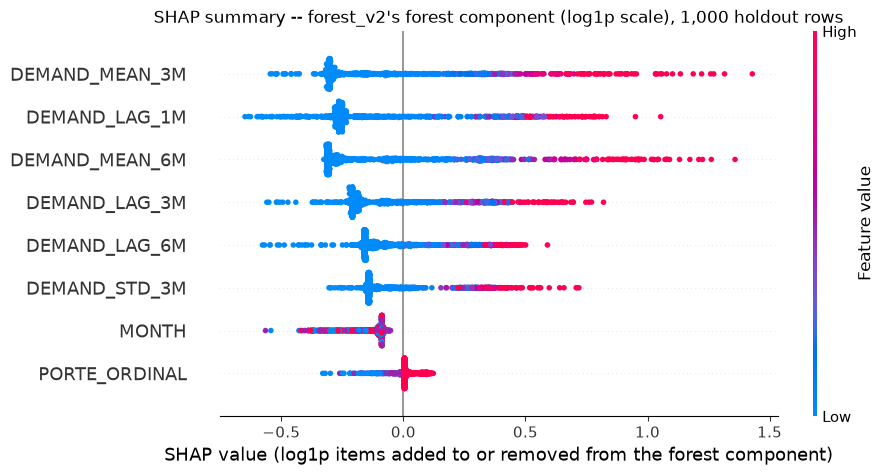

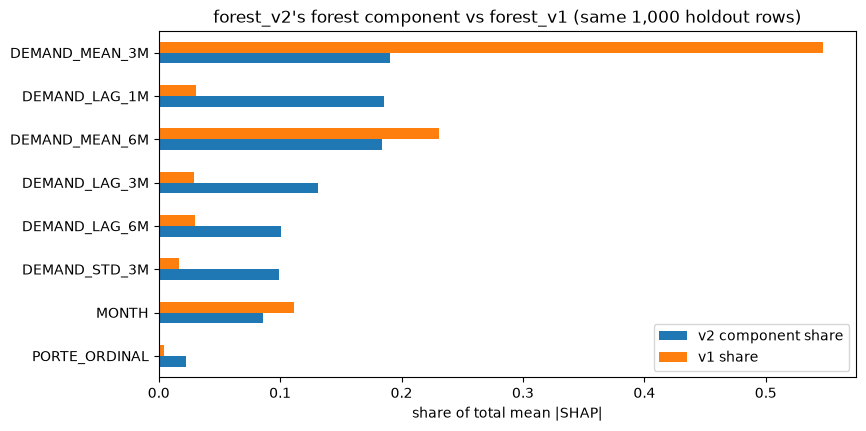

In [24]:
shap.plots.beeswarm(shap_v2, max_display=len(APPROVED_X), show=False)
fig = plt.gcf()
fig.set_size_inches(9, 5)
plt.title(f"SHAP summary -- forest_v2's forest component (log1p scale), {len(shap_X):,} holdout rows")
plt.xlabel("SHAP value (log1p items added to or removed from the forest component)")
fig.savefig(ASSETS / "demand-rf-v2-shap-beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
share[["v2 component share", "v1 share"]].iloc[::-1].plot.barh(ax=ax)
ax.set_xlabel("share of total mean |SHAP|")
ax.set_title("forest_v2's forest component vs forest_v1 (same 1,000 holdout rows)")
fig.savefig(ASSETS / "demand-rf-v2-vs-v1-shap-share.png", dpi=150, bbox_inches="tight")
plt.show()

In [25]:
# MONTH: does v2 still carry September forward? Highest MONTH threshold in any tree.
month_idx = APPROVED_X.index("MONTH")
thresholds = np.concatenate([t.tree_.threshold[t.tree_.feature == month_idx] for t in v2_forest.estimators_])
print(f"MONTH splits in forest_v2: {len(thresholds):,} | highest threshold: {thresholds.max():.1f} | mean |SHAP| "
      f"of MONTH in the forest component: {share.loc['MONTH', 'v2 component mean |SHAP| (log1p)']:.3f} log1p")

MONTH splits in forest_v2: 31,553 | highest threshold: 8.5 | mean |SHAP| of MONTH in the forest component: 0.137 log1p


**Reading — the forest component only.** These values describe the forest inside `forest_v2`, on
the `log1p` scale. Section 13.1 checks what carries over to the published forecast.

- **The component spreads its attribution across the history predictors.** The top three are nearly
  tied: `DEMAND_MEAN_3M` 19.0%, `DEMAND_LAG_1M` 18.6% and `DEMAND_MEAN_6M` 18.4% of total mean
  |SHAP|, where `forest_v1` gives `DEMAND_MEAN_3M` 54.7%. This is the direct effect of
  `max_features = 1`: each split sees one random predictor, so every history column has to carry
  part of the forest's forecast. The two rankings still agree broadly (Spearman 0.690), with the
  same leader and the same last place.
- **`PORTE_ORDINAL` is last** in the component too (2.3%).
- **`MONTH` falls from third to seventh** (8.6% against 11.1%), but its highest split threshold in
  all 600 trees is still 8.5, so October to December are still routed down September's branch
  (Section 4.4.5.3).
- **The reference point changed.** The component's expected value is 1.592 in `log1p` units
  (3.9 items), not 61.6 items: a log fit centres on the typical unit rather than on the arithmetic
  mean of the training target.

### 13.1 The complete recipe, on the item scale

The component values above do not show how much each predictor moves the **published** forecast:
`expm1` stretches contributions differently at different forecast levels, and the blend adds
`0.3 × DEMAND_LAG_1M` outside the forest. The published function

`f(x) = 0.7 · expm1(forest(x)) + 0.3 · DEMAND_LAG_1M (0 where missing)`

is therefore explained directly, with **exact** Shapley values (all 2⁸ coalitions of the eight
predictors) against an interventional background of 100 training rows. SHAP values are then in
items per month, and `base value + Σ SHAP` must equal the published forecast. Exact enumeration costs
25,600 forecasts per explained row, so 300 of the 1,000 rows above are explained, and the component
and `forest_v1` shares are recomputed on the same 300 rows for the comparison.

complete recipe: 300 rows in 163 s | base value 11.89 items | additivity gap 3.3e-12
Spearman, recipe vs component: 0.905 | recipe vs forest_v1: 0.619


,recipe (items),component (log1p),forest_v1 (items),recipe share,component share,forest_v1 share,recipe rank,component rank,forest_v1 rank
DEMAND_LAG_1M,12.648,0.287,2.286,0.510,0.185,0.030,1,2,6
DEMAND_MEAN_3M,3.275,0.297,42.011,0.132,0.192,0.555,2,1,1
DEMAND_MEAN_6M,2.989,0.284,16.705,0.121,0.184,0.221,3,3,2
DEMAND_LAG_3M,1.941,0.209,2.459,0.078,0.135,0.032,4,4,4
MONTH,1.555,0.132,8.531,0.063,0.085,0.113,5,7,3
DEMAND_LAG_6M,1.149,0.156,2.372,0.046,0.101,0.031,6,5,5
DEMAND_STD_3M,0.736,0.150,0.997,0.030,0.097,0.013,7,6,7
PORTE_ORDINAL,0.492,0.033,0.368,0.020,0.021,0.005,8,8,8


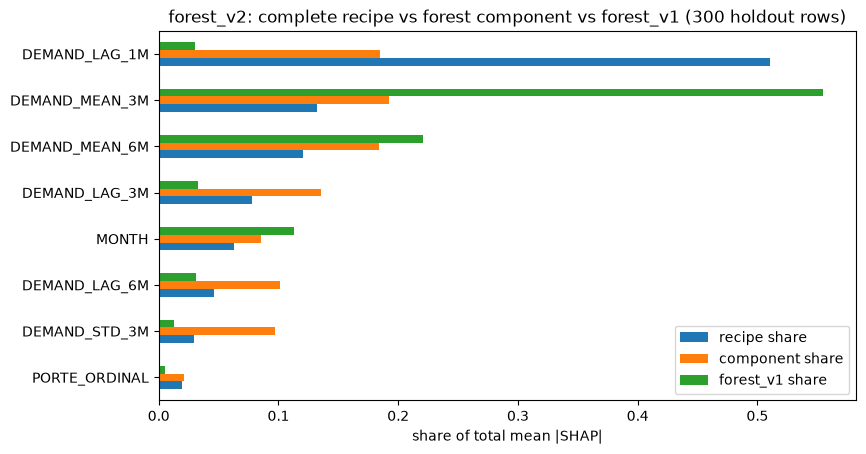

In [26]:
def published_forecast(X):
    frame = pd.DataFrame(np.asarray(X, dtype=float), columns=APPROVED_X)
    return predict_v2(bundle["model"], frame, bundle["metadata"]["blend"]["forest_weight"])


background = train[APPROVED_X].sample(100, random_state=RANDOM_STATE)
recipe_X = shap_X.iloc[:300]
t0 = time.perf_counter()
explainer_full = shap.Explainer(published_forecast, shap.maskers.Independent(background, max_samples=100),
                                algorithm="exact", feature_names=APPROVED_X)
shap_full = explainer_full(recipe_X, silent=True)
full_pred = published_forecast(recipe_X)
full_gap = float(np.abs(shap_full.base_values + shap_full.values.sum(axis=1) - full_pred).max())
assert full_gap < 1e-6 * max(1.0, float(full_pred.max())), f"recipe SHAP not additive: {full_gap:.3g}"
assert np.allclose(full_pred, hold_pred["Random Forest v2 (selected)"][holdout.index.get_indexer(recipe_X.index)]), \
    "the explained function is not the published forecast"
print(f"complete recipe: {len(recipe_X)} rows in {time.perf_counter() - t0:.0f} s | base value "
      f"{float(np.ravel(shap_full.base_values)[0]):.2f} items | additivity gap {full_gap:.1e}")

rows_idx = shap_X.index.get_indexer(recipe_X.index)
levels = pd.DataFrame({
    "recipe (items)": np.abs(shap_full.values).mean(axis=0),
    "component (log1p)": np.abs(shap_v2.values[rows_idx]).mean(axis=0),
    "forest_v1 (items)": np.abs(shap_v1.values[rows_idx]).mean(axis=0)}, index=APPROVED_X)
recipe_share = levels / levels.sum()
recipe_share.columns = [f"{c.split(' (')[0]} share" for c in levels.columns]
recipe_share = recipe_share.sort_values("recipe share", ascending=False)
ranks = recipe_share.rank(ascending=False).astype(int)
ranks.columns = [c.replace("share", "rank") for c in ranks.columns]
print(f"Spearman, recipe vs component: "
      f"{recipe_share['recipe share'].corr(recipe_share['component share'], method='spearman'):.3f} | "
      f"recipe vs forest_v1: {recipe_share['recipe share'].corr(recipe_share['forest_v1 share'], method='spearman'):.3f}")
display(pd.concat([levels.loc[recipe_share.index].round(3), recipe_share.round(3), ranks], axis=1))

fig, ax = plt.subplots(figsize=(9, 4.8))
recipe_share.iloc[::-1].plot.barh(ax=ax)
ax.set_xlabel("share of total mean |SHAP|")
ax.set_title(f"forest_v2: complete recipe vs forest component vs forest_v1 ({len(recipe_X)} holdout rows)")
fig.savefig(ASSETS / "demand-rf-v2-shap-recipe-share.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading — the complete recipe.** The component's shares do **not** carry over to the published
forecast; the rank order largely does.

- **`DEMAND_LAG_1M` dominates the published forecast** with 51.0% of total mean |SHAP|, against
  18.5% in the forest component. Most of that is the blend itself: `0.3 × DEMAND_LAG_1M` is additive,
  so its whole effect lands on that one predictor, on top of the forest's use of it.
- **The rolling means drop to 13.2% and 12.1%,** where the component gives them about 19% each. In
  items, the forest's contributions are scaled by the 0.7 weight and by the slope of `expm1` at
  each row's forecast level, while the direct term `0.3 × DEMAND_LAG_1M` is not, so the balance
  shifts toward last month's value.
- **The ordering is broadly preserved** (Spearman 0.905 between recipe and component): the history
  predictors lead, and `PORTE_ORDINAL` is last (2.0%), so **H1** holds for the published forecast
  too. `MONTH` is fifth (6.3%).
- **Against `forest_v1`, the published forecasts rest on different inputs** (Spearman 0.619):
  `forest_v1` is driven by `DEMAND_MEAN_3M` (55.5%), `forest_v2` by last month's value. For a
  non-technical reader, `forest_v2` forecasts next month mostly from last month's billed volume,
  corrected by the recent level. `forest_v1` forecasts it from the three-month average.

The explanation is exact for the function the prediction base publishes (additivity gap
below 10⁻¹¹ items, base value 11.89 items), against a background of 100 training rows; a different
background would move the base value and, to a lesser degree, the shares.

## 14. A promotion gate for the prediction base

Section 10's rule picks the **validation leader**. Replacing the published prediction base is a
different decision. The base feeds the `tier` list, so a challenger should replace the incumbent only
if it is at least as good at what that list is used for. The holdout showed that the selection rule
does not guarantee this: `forest_v2` met the pooled volume band on validation and missed it on the
holdout, and the rule says nothing about observed rows or about the ranking itself.

**How production tiers are assigned.** The prediction base (Section 12, and notebook 17 for
`forest_v1`) labels a row `alto`, `medio` or `baixo` from the terciles of predicted volume over
**every row scored in one publication**, including rows whose target cannot be measured. The
current files are one publication covering October–December (3,843 rows). From here on, the gate
assumes **one publication per forecast month**: the terciles are taken over all rows scored for that
month. The gate evaluates that tier assignment exactly; the actual volume needed to score it exists
only for measured rows, so capture and correlation are computed on those.

The gate applies to any future challenger of the incumbent base (today `forest_v1`), on monthly
forecast origins that took no part in selecting the challenger. A challenger replaces the base only
if all four criteria pass on at least three such months:

| # | Criterion | Why |
|---|---|---|
| G1 | Skill against the naive forecast above 0 on every month but at most one | The model must beat a forecast that needs no fitting |
| G2 | Volume ratio within [0.90, 1.10] on **every** month, absolute and not pooled | The dashboard sums predicted volume; a pooled band hid the holdout miss |
| G3 | Observed-row MAE no higher than the incumbent's on a majority of months, **and** a by-operator bootstrap does not find the pooled observed-row difference significantly positive | The rows that billed are the ones the business acts on |
| G4 | **Published `alto` tier, non-inferior:** the share of measured volume billed by rows in the published `alto` tier is at least the incumbent's minus **1.0 percentage point** on a majority of months, **and** the mean Spearman correlation between predicted and measured volume is at least the incumbent's minus **0.02** | The `tier` list is a ranking; forecast error alone does not show which list ranks better, and a negligible difference should not block or justify a switch |

**Status of the thresholds.** The volume band of G2 and the two margins of G4 are proposals for the
business team to confirm before the gate's first real use. The review kept G2 absolute: an incumbent
that misses the band is a reason to monitor its own volume error, not to relax the standard. The G4
margins were chosen after seeing the descriptive comparison below, where the two tier lists differ by
0.4 points, so they cannot be validated on these months. This is one more reason why applying the
gate to the validation and holdout months, which have already been seen, is a **description only**.
It cannot change Section 10's choice. It tests whether keeping `forest_v1` still holds once the
published tier is evaluated directly.

A **monthly ranking diagnostic** is reported separately from G4: on measured rows only, the top third
of each month's rows by prediction, the share of that month's volume it captures against the best
possible ranking, and the recall of the month's largest billing units (top 10% of the units that
billed). It describes ranking quality without the tier rule's unmeasurable rows, but it is not the
tier the dashboard receives.

In [27]:
CAPTURE_MARGIN = 0.010    # G4: 1.0 percentage point of measured volume (proposal, business to confirm)
SPEARMAN_MARGIN = 0.02    # G4: rank correlation (proposal, business to confirm)


def published_tiers(pred):
    # the prediction base's rule (Section 12 and notebook 17): terciles over every scored row
    q1, q2 = np.quantile(pred, [1 / 3, 2 / 3])
    return np.select([pred <= q1, pred <= q2], ["baixo", "medio"], default="alto")


def tier_quality(tier, pred, actual, measured):
    alto = np.asarray(tier) == "alto"
    y, a, p = np.asarray(actual, float)[measured], alto[measured], np.asarray(pred, float)[measured]
    best = np.sort(y)[::-1][:a.sum()].sum()
    return {"rows_scored": len(alto), "rows_measured": int(measured.sum()), "alto_share": alto.mean(),
            "alto_capture": y[a].sum() / y.sum(), "best_capture": best / y.sum(),
            "spearman": pd.Series(p).corr(pd.Series(y), method="spearman")}


GATE_MODELS = {
    "forest_v1": forest(**RF_V1),
    "forest_v2": blend(forest(log_target=True, **FINAL_PARAMS), WINNER_WEIGHT),
    "naive (reference)": lambda tr, va: naive_forecast(va),
}

# (a) The files the dashboard receives, exactly as published: one October-December publication.
v1_published = pd.read_parquet(PROC / "north_region_mama_2025_demand_predictions_forest_v1.parquet")
published = {"forest_v1": v1_published, "forest_v2": pred_base}
as_published = []
for name, base_ in published.items():
    assert len(base_) == len(scoring), f"{name}: the published base does not cover the scored rows"
    measured = base_["target_measured"].to_numpy(bool)
    as_published.append({"model": name, **tier_quality(base_["tier"].to_numpy(), base_["volume_previsto"].to_numpy(),
                                                      base_["volume_observado"].fillna(0).to_numpy(), measured)})
naive_scored = naive_forecast(scoring)
as_published.append({"model": "naive (reference)", **tier_quality(
    published_tiers(naive_scored), naive_scored, scoring[TARGET].where(scoring["USABLE"], 0).to_numpy(),
    scoring["USABLE"].to_numpy(bool))})
print("Published tier, October-December publication (tiers over all scored rows, scored on measured rows):")
display(pd.DataFrame(as_published).set_index("model").round(3))

# (b) The production rule for future origins: one publication per month, tiers over all its scored rows.
tier_rows, diag_rows, gate_preds = [], [], {}
batches = [("validation", o, panel[panel["MES"] == o], tr) for o, (tr, _) in zip(ORIGINS, FOLDS)]
batches += [("holdout", pd.Timestamp(m), scoring[scoring["MES"] == m], train) for m in sorted(holdout["MES"].unique())]
for period, month, scored, fit_rows in batches:
    measured = scored["USABLE"].to_numpy(bool)
    actual = scored[TARGET].where(scored["USABLE"], 0).to_numpy(dtype=float)
    preds = {n: np.clip(fn(fit_rows, scored), 0, None) for n, fn in GATE_MODELS.items()}
    for name, pred in preds.items():
        tier_rows.append({"period": period, "month": f"{month:%Y-%m}", "model": name,
                          **tier_quality(published_tiers(pred), pred, actual, measured)})
    # measured rows only, for G1-G3 and the monthly diagnostic
    frame = scored[measured]
    gate_preds[(period, month)] = (frame, {n: p[measured] for n, p in preds.items()})
tier_table = pd.DataFrame(tier_rows)
tier_table.pivot_table(index=["period", "month"], columns="model", values=["alto_capture", "spearman"]).round(3)

Published tier, October-December publication (tiers over all scored rows, scored on measured rows):


,rows_scored,rows_measured,alto_share,alto_capture,best_capture,spearman
model,,,,,,
forest_v1,3843,3810,0.333,0.967,0.997,0.677
forest_v2,3843,3810,0.333,0.963,0.997,0.710
naive (reference),3843,3810,0.299,0.901,0.995,0.679


alto_capture                              spearman                            
model                 forest_v1 forest_v2 naive (reference) forest_v1 forest_v2 naive (reference)
period     month                                                                                 
holdout    2025-10        0.967     0.964             0.906     0.705     0.736             0.704
           2025-11        0.958     0.950             0.887     0.689     0.714             0.676
           2025-12        0.976     0.974             0.911     0.638     0.681             0.661
validation 2025-05        0.988     0.987             0.968     0.780     0.798             0.750
           2025-06        0.987     0.984             0.950     0.750     0.751             0.711
           2025-07        0.988     0.984             0.952     0.770     0.802             0.738
           2025-08        0.987     0.986             0.976     0.748     0.759             0.714
           2025-09        0.986     0.985             0.940     0.671     0.678             0.638

In [28]:
def ranking_diagnostic(y, pred):
    # monthly ranking diagnostic on measured rows (not the published tier)
    y, pred = np.asarray(y, dtype=float), np.asarray(pred, dtype=float)
    k = len(y) // 3
    in_top = np.zeros(len(y), bool)
    in_top[np.argsort(-pred, kind="mergesort")[:k]] = True
    billed = np.flatnonzero(y > 0)
    largest = billed[np.argsort(-y[billed], kind="mergesort")[:max(1, int(np.ceil(0.1 * len(billed))))]]
    return {"top_third_capture": y[in_top].sum() / y.sum(), "best_top_third": np.sort(y)[::-1][:k].sum() / y.sum(),
            "top_decile_recall": in_top[largest].mean()}


gate_rows = []
for (period, month), (frame, preds) in gate_preds.items():
    y = frame[TARGET].to_numpy(dtype=float)
    obs = ~frame["IS_STRUCTURAL_ZERO"].to_numpy()
    naive_mae = mean_absolute_error(y, naive_forecast(frame))
    for name, pred in preds.items():
        gate_rows.append({"period": period, "month": f"{month:%Y-%m}", "model": name,
                          "skill": 1 - mean_absolute_error(y, pred) / naive_mae,
                          "volume_ratio": pred.sum() / y.sum(),
                          "MAE_obs": mean_absolute_error(y[obs], pred[obs]),
                          **ranking_diagnostic(y, pred)})
gate_table = pd.DataFrame(gate_rows)
print("Monthly ranking diagnostic (measured rows only; not the published tier):")
gate_table.groupby(["period", "model"])[["top_third_capture", "best_top_third", "top_decile_recall"]].mean().round(3)

Monthly ranking diagnostic (measured rows only; not the published tier):


top_third_capture  best_top_third  top_decile_recall
period     model                                                                  
holdout    forest_v1                      0.967           0.996              0.982
           forest_v2                      0.963           0.996              0.982
           naive (reference)              0.903           0.996              0.941
validation forest_v1                      0.987           0.994              1.000
           forest_v2                      0.985           0.994              1.000
           naive (reference)              0.959           0.994              0.974

In [29]:
def pooled_obs_diff_ci(period, challenger, incumbent, n_boot=2000):
    # by-operator bootstrap of the pooled observed-row MAE difference (challenger - incumbent)
    frames = [(f, p) for (per, _), (f, p) in gate_preds.items() if per == period]
    y = np.concatenate([f[TARGET].to_numpy(dtype=float) for f, _ in frames])
    obs = np.concatenate([~f["IS_STRUCTURAL_ZERO"].to_numpy() for f, _ in frames])
    ops = np.concatenate([f["ID_PLANO"].astype(str).to_numpy() for f, _ in frames])
    err_c = np.abs(y - np.concatenate([p[challenger] for _, p in frames]))
    err_i = np.abs(y - np.concatenate([p[incumbent] for _, p in frames]))
    codes, idx = np.unique(ops[obs], return_inverse=True)
    diff_sum = np.bincount(idx, weights=(err_c - err_i)[obs], minlength=len(codes))
    counts = np.bincount(idx, minlength=len(codes))
    rng_ = np.random.default_rng(RANDOM_STATE)
    w = np.stack([np.bincount(rng_.integers(0, len(codes), len(codes)), minlength=len(codes)) for _ in range(n_boot)])
    d = (w @ diff_sum) / (w @ counts)
    return float(np.quantile(d, 0.025)), float(np.quantile(d, 0.975))


def apply_gate(period, challenger="forest_v2", incumbent="forest_v1"):
    t = gate_table[gate_table["period"] == period].pivot(index="month", columns="model")
    r = tier_table[tier_table["period"] == period].pivot(index="month", columns="model")
    n = len(t)
    low, high = pooled_obs_diff_ci(period, challenger, incumbent)
    capture_ok = (r["alto_capture"][challenger] >= r["alto_capture"][incumbent] - CAPTURE_MARGIN)
    spearman_c, spearman_i = r["spearman"][challenger].mean(), r["spearman"][incumbent].mean()
    checks = {
        "G1 skill > 0 on all months but one": ((t["skill"][challenger] > 0).sum() >= n - 1,
                                                f"{(t['skill'][challenger] > 0).sum()}/{n} months"),
        "G2 volume ratio in band on every month": (t["volume_ratio"][challenger].between(*VOLUME_BAND).all(),
                                                   ", ".join(f"{v:.2f}" for v in t["volume_ratio"][challenger])),
        "G3 observed-row MAE vs incumbent": (
            ((t["MAE_obs"][challenger] <= t["MAE_obs"][incumbent]).sum() > n / 2) and low <= 0,
            f"no worse on {(t['MAE_obs'][challenger] <= t['MAE_obs'][incumbent]).sum()}/{n}; "
            f"pooled diff 95% CI [{low:.2f}, {high:.2f}]"),
        "G4 published alto tier, non-inferior": (
            capture_ok.sum() > n / 2 and spearman_c >= spearman_i - SPEARMAN_MARGIN,
            f"capture within {CAPTURE_MARGIN:.1%} on {capture_ok.sum()}/{n} "
            f"(largest shortfall {(r['alto_capture'][incumbent] - r['alto_capture'][challenger]).max():.2%}); "
            f"mean Spearman {spearman_c:.3f} vs {spearman_i:.3f}"),
    }
    return pd.DataFrame([{"period": period, "criterion": c, "pass": ok, "evidence": ev} for c, (ok, ev) in checks.items()])


gate_result = pd.concat([apply_gate("validation"), apply_gate("holdout")], ignore_index=True)
with pd.option_context("display.max_colwidth", 130):
    display(gate_result)
for period in ("validation", "holdout"):
    passed = gate_result.loc[gate_result["period"] == period, "pass"].all()
    print(f"{period}: forest_v2 {'passes' if passed else 'does not pass'} the gate against forest_v1 (descriptive)")

,period,criterion,pass,evidence
0,validation,G1 skill > 0 on all months but one,True,5/5 months
1,validation,G2 volume ratio in band on every month,False,"0.75, 0.83, 0.85, 1.06, 1.21"
2,validation,G3 observed-row MAE vs incumbent,True,"no worse on 3/5; pooled diff 95% CI [-6.38, -1.38]"
3,validation,"G4 published alto tier, non-inferior",True,capture within 1.0% on 5/5 (largest shortfall 0.44%); mean Spearman 0.757 vs 0.744
4,holdout,G1 skill > 0 on all months but one,True,2/3 months
5,holdout,G2 volume ratio in band on every month,False,"0.57, 0.76, 0.68"
6,holdout,G3 observed-row MAE vs incumbent,False,"no worse on 0/3; pooled diff 95% CI [5.01, 8.82]"
7,holdout,"G4 published alto tier, non-inferior",True,capture within 1.0% on 3/3 (largest shortfall 0.81%); mean Spearman 0.710 vs 0.678


validation: forest_v2 does not pass the gate against forest_v1 (descriptive)
holdout: forest_v2 does not pass the gate against forest_v1 (descriptive)


**Reading.** `forest_v2` does not pass the gate on either set of months, and the failure has nothing
to do with the `tier` list:

| Criterion | Validation (5 months) | Holdout (3 months) |
|---|---|---|
| G1 skill above 0 | pass (5/5) | pass (2/3) |
| G2 volume ratio in band on every month | **fail** (0.75 to 1.21) | **fail** (0.57 to 0.76) |
| G3 observed-row MAE vs `forest_v1` | pass: significantly **better**, 95% interval [−6.38, −1.38] | **fail**: significantly worse, [5.01, 8.82] |
| G4 published `alto` tier, non-inferior | pass: largest shortfall 0.44 points; Spearman 0.757 vs 0.744 | pass: largest shortfall 0.81 points; Spearman 0.710 vs 0.678 |

- **The published tier lists are nearly equivalent.** Evaluated exactly as the dashboard receives
  them (terciles over all 3,843 scored rows of the October–December publication, scored on the 3,810
  measured rows), the `alto` tier holds 96.7% of measured volume for `forest_v1` and 96.3% for
  `forest_v2`, against a best possible 99.7%. `forest_v2` orders the whole list slightly better
  (Spearman 0.710 against 0.677). Both clearly beat last month's value (90.1%). With one publication
  per month, `forest_v2` stays within the 1-point margin in all eight months. **Keeping `forest_v1`
  therefore rests on G2 and G3, not on the ranking:** `forest_v2` under-predicts volume in every
  holdout month and is worse on the rows that billed.
- **The monthly ranking diagnostic tells the same story** (top third 96.7% against 96.3% on the
  holdout, identical top-decile recall of 98.2%), now that it is labelled as a diagnostic, not as
  the published tier.
- **G3 reverses between the two periods.** On validation, `forest_v2` is significantly better than
  `forest_v1` on observed rows; on the holdout it is significantly worse. This is the
  validation–holdout disagreement of Section 11, measured directly, and it is why the gate asks for
  new months rather than trusting either period alone.
- **G2 stays absolute.** `forest_v1` itself misses the band on four of the eight months (1.11, 1.35
  and 1.71 in July to September, 0.899 in October). Following the review, that is a reason to monitor
  the incumbent's own volume error, not to make the criterion relative. The band and the G4 margins
  await the business team's confirmation.

## 15. Conclusions and limitations

**What improved.**

- **On validation, the gap to the linear models is closed.** Three-origin MAE falls from 31.01 to
  23.95, now the lowest of any family, and mean skill over five origins rises from +0.037 to +0.178.
  Most of the gain comes from two changes: fitting `log1p(y)`, and drawing one predictor per split.
- **On the holdout,** `forest_v2` has the best RMSE and R² of every candidate so far. It is the only
  model whose all-rows gain over the naive forecast survives a by-operator bootstrap, and it doubles
  `forest_v1`'s skill at the operator grain. Its all-rows MAE ties `forest_v1`'s within seed noise
  (Section 11.3), and its published `alto` tier is non-inferior to `forest_v1`'s (Section 14).

**What did not.**

- **It is significantly worse than `forest_v1` on observed rows** of the holdout, for every seed.
- **It under-predicts holdout volume by a third,** so the validation volume guardrail did not hold
  out of sample.
- **It does not pass the promotion gate** of Section 14, on volume (G2) and holdout observed rows
  (G3). The ranking criterion (G4) passes.

**Decision.** `forest_v2` becomes the **validation leader, with a final holdout estimate**. It is
**not** a replacement for `forest_v1`'s prediction base:

- the registry marks it `selected: false`;
- the dashboard keeps reading `forest_v1`;
- the seasonal-naive forecast stays the operator-level default until Section 4.3.9.9's live trigger
  is met.

**Reproducibility.** Every number above comes from the inputs fingerprinted in Section 1, with the
row order pinned and the seed fixed at 42, and from the code identified by `notebook_code_sha256`,
which the last cell checks against the code actually executed. The notebook stops if the matrix
differs from the documented run, if a headline result is not reproduced, or if the executed code is
not the notebook's code.

**Limitations.**

- **One calendar year.** Five origins are still a small sample: nested selection shows an optimism
  of 0.092 skill points, and the top eligible candidates are not reliably separable.
- **The gate's thresholds are proposals.** The volume band of G2 and the margins of G4 (1.0 point of
  captured volume, 0.02 of Spearman) await the business team's confirmation. The margins were set
  after the descriptive comparison, so the gate's application to the months above is a description,
  not evidence for or against it.
- **The hurdle model** (best observed-row skill in validation, volume ratio 1.023) was not read on
  the holdout, and its positive amounts are a back-transformed log-scale fit, not a conditional
  median.
- **`MONTH` still extrapolates September**, and **the sudden-start failure** still needs predictors
  from outside the claims history.

**Next.** Once the business team confirms the thresholds, apply Section 14's gate to `forest_v2`
and the hurdle model against `forest_v1`, with one publication per forecast month, as 2026 months
arrive. The prediction base should move only to a challenger that passes all four criteria on at
least three new months.

### Code provenance check

The provenance block of Section 1 identifies the code by a hash of this notebook's code cells, not by
a repository commit, which can differ from the code that actually ran. This last cell closes the
loop: it compares every code cell executed in this session, in order, with the code cells of the
notebook file that hash was computed from.

In [30]:
executed_code = [src.strip() for src in get_ipython().user_ns["In"][1:] if src.strip()]
assert executed_code == NOTEBOOK_CODE, (
    "The code executed in this session is not the code of notebooks/20_demand_model_improvement.ipynb: "
    "run the notebook top to bottom from a fresh kernel before committing its outputs.")
print(f"all {len(executed_code)} executed code cells match the notebook file | "
      f"notebook_code_sha256 = {PROVENANCE['notebook_code_sha256']}")

all 30 executed code cells match the notebook file | notebook_code_sha256 = 531dac4ecc5f1089


## References

1. Breiman L. Random forests. Mach Learn. 2001;45(1):5-32.
2. Duan N. Smearing estimate: a nonparametric retransformation method. J Am Stat Assoc. 1983;78(383):605-10.
3. Hyndman RJ, Koehler AB. Another look at measures of forecast accuracy. Int J Forecast. 2006;22(4):679-88.